In [83]:
# ===== PART 0 | CELL 0.1: imports + Kaggle paths =====
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

ON_KAGGLE = os.path.exists('/kaggle/input')
INPUT_ROOT = '/kaggle/input' if ON_KAGGLE else '.'            # where added datasets live (read-only)
OUT = '/kaggle/working' if ON_KAGGLE else './kaggle_working'  # where we save our outputs
for sub in ['data', 'figures', 'forecasts', 'metrics']:
    os.makedirs(f'{OUT}/{sub}', exist_ok=True)

def find_file(name, root=INPUT_ROOT):
    for dirpath, _, files in os.walk(root):
        if name in files:
            return os.path.join(dirpath, name)
    return None

In [84]:
# ===== PART 0 | CELL 0.2: locate the raw file =====
RAW_PATH = find_file('IEX_Market_Data.csv')
assert RAW_PATH, "Raw file not found: click 'Add Input' on the right and add your IEX dataset first"
print('Raw file :', RAW_PATH)
print('Size (MB):', round(os.path.getsize(RAW_PATH) / 1e6, 1))

Raw file : /kaggle/input/datasets/saurav0214/iex-data/IEX_Market_Data.csv
Size (MB): 21.3


Part 1: clean DAM series

In [85]:
# ===== PART 1 | CELL 1.1: load raw file (read only) =====
raw = pd.read_csv(RAW_PATH, low_memory=False)
print('Raw shape:', raw.shape); print(raw['TYPE'].value_counts())

Raw shape: (289214, 13)
TYPE
DAM     96480
GDAM    96480
RTM     96254
Name: count, dtype: int64


In [86]:
# ===== PART 1 | CELL 1.2: build our own clean DAM series =====
df = raw.iloc[:, :8].copy()
df.columns = ['market', 'year', 'date', 'block_time', 'demand', 'supply', 'mcp', 'mcv']
for c in ['demand', 'supply', 'mcp', 'mcv']:
    df[c] = pd.to_numeric(df[c], errors='coerce')
df['timestamp'] = pd.to_datetime(df['date'] + ' ' + df['block_time'])
dam = (df[df['market'] == 'DAM'].sort_values('timestamp')
         .set_index('timestamp')[['mcp', 'demand', 'supply', 'mcv']])
print('DAM series:', dam.shape, '|', dam.index.min(), '->', dam.index.max())

DAM series: (96480, 4) | 2023-01-01 00:00:00 -> 2025-10-01 23:45:00


In [87]:
# ===== PART 1 | CELL 1.3: quality report =====
expected = pd.date_range(dam.index.min(), dam.index.max(), freq='15min')
per_day = dam.groupby(dam.index.date).size()
report = pd.Series({
    'Observations': len(dam), 'Start': dam.index.min(), 'End': dam.index.max(),
    'Missing timestamps': len(expected.difference(dam.index)),
    'Duplicate timestamps': int(dam.index.duplicated().sum()),
    'Days with exactly 96 blocks': f'{int((per_day == 96).sum())} of {per_day.size}',
    'Missing MCP': int(dam['mcp'].isna().sum()),
    'Missing demand / supply / MCV': f"{dam['demand'].isna().sum()} / {dam['supply'].isna().sum()} / {dam['mcv'].isna().sum()}",
    'Negative or zero MCP': int((dam['mcp'] <= 0).sum()),
    'MCP min / max': f"{dam['mcp'].min():.2f} / {dam['mcp'].max():.2f}",
})
print(report.to_string())

Observations                                   96480
Start                            2023-01-01 00:00:00
End                              2025-10-01 23:45:00
Missing timestamps                                 0
Duplicate timestamps                               0
Days with exactly 96 blocks             1005 of 1005
Missing MCP                                        0
Missing demand / supply / MCV              0 / 0 / 0
Negative or zero MCP                               0
MCP min / max                           0.05 / 12.00


In [88]:
# ===== PART 1 | CELL 1.4: save outputs =====
dam.to_csv(f'{OUT}/data/dam_clean.csv', index_label='timestamp')
report.astype(str).to_csv(f'{OUT}/metrics/quality_report.csv', header=['value'])
print('Saved:', f'{OUT}/data/dam_clean.csv')

Saved: /kaggle/working/data/dam_clean.csv


In [89]:
# ===== PART 1 | CELL 1.5: reload test =====
dam2 = pd.read_csv(f'{OUT}/data/dam_clean.csv', parse_dates=['timestamp'], index_col='timestamp')
print('Reload OK:', dam2.shape, '| identical:', np.allclose(dam.values, dam2.values))

Reload OK: (96480, 4) | identical: True


Part 2: split, metrics, baselines

train 2023-01-01 00:00:00 -> 2025-03-31 23:45:00 |  78816 blocks |  821 days | mean MCP 4.99 | min 0.30
val   2025-04-01 00:00:00 -> 2025-06-30 23:45:00 |   8736 blocks |   91 days | mean MCP 4.41 | min 0.10
test  2025-07-01 00:00:00 -> 2025-10-01 23:45:00 |   8928 blocks |   93 days | mean MCP 3.92 | min 0.05


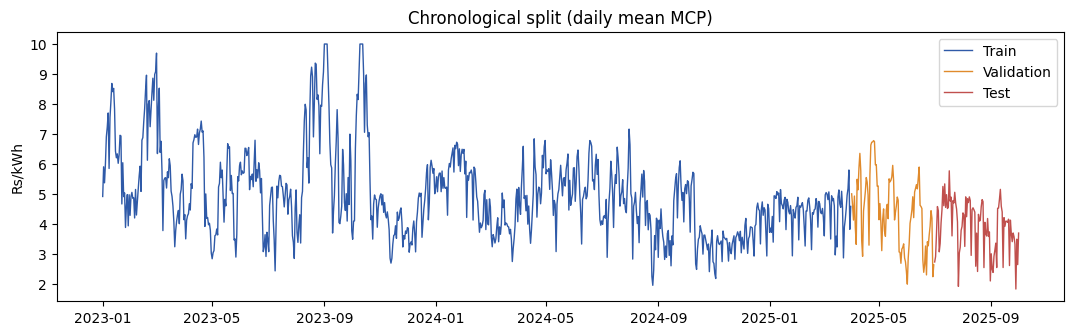

In [90]:
# ===== PART 2 | CELL 2.1: chronological train / validation / test split =====
TRAIN_END = '2025-03-31 23:45'
VAL_START, VAL_END = '2025-04-01 00:00', '2025-06-30 23:45'
TEST_START = '2025-07-01 00:00'

train = dam.loc[:TRAIN_END]
val   = dam.loc[VAL_START:VAL_END]
test  = dam.loc[TEST_START:]
for name, part in [('train', train), ('val', val), ('test', test)]:
    print(f'{name:5s} {part.index.min()} -> {part.index.max()} | {len(part):6d} blocks | '
          f'{len(part)//96:4d} days | mean MCP {part.mcp.mean():.2f} | min {part.mcp.min():.2f}')

fig, ax = plt.subplots(figsize=(13, 3.5))
for part, c, lab in [(train, '#2f5aa8', 'Train'), (val, '#e08a2c', 'Validation'), (test, '#c0504d', 'Test')]:
    ax.plot(part['mcp'].resample('D').mean(), color=c, label=lab, lw=1)
ax.set_title('Chronological split (daily mean MCP)'); ax.set_ylabel('Rs/kWh'); ax.legend()
plt.savefig(f'{OUT}/figures/split.png', dpi=150, bbox_inches='tight'); plt.show()

In [91]:
# ===== PART 2 | CELL 2.2: metrics + evaluation helper =====
def hourly(s):                     return s.resample('h').mean()
def hourly_to_15min(ph, idx15):    return ph.reindex(idx15, method='ffill')   # repeat each hourly value for its 4 blocks

def seasonal_scale(y, m):          return np.mean(np.abs(y[m:] - y[:-m]))     # in-sample seasonal-naive MAE (for MASE)
SCALE15 = seasonal_scale(train['mcp'].values, 96)
SCALE_H = seasonal_scale(hourly(train['mcp']).values, 24)

def metrics(y, p, scale):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = y - p
    return {'MAE': np.mean(np.abs(e)), 'RMSE': np.sqrt(np.mean(e ** 2)),
            'MAPE_%': np.mean(np.abs(e) / np.abs(y)) * 100,
            'sMAPE_%': np.mean(2 * np.abs(e) / (np.abs(y) + np.abs(p))) * 100,
            'MASE': np.mean(np.abs(e)) / scale}

RESULTS = []
def evaluate(name, pred15):
    """pred15 = forecast Series on the 15-minute timestamps. Scores it on validation and test, at 15-min and hourly level."""
    rows = []
    for split, part in [('val', val), ('test', test)]:
        y = part['mcp']; p = pred15.reindex(y.index)
        ok = p.notna()
        rows.append({'model': name, 'split': split, 'level': '15-min', 'n': int(ok.sum()), **metrics(y[ok], p[ok], SCALE15)})
        yh, ph = hourly(y[ok]), hourly(p[ok])
        rows.append({'model': name, 'split': split, 'level': 'hourly', 'n': int(len(yh)), **metrics(yh, ph, SCALE_H)})
    RESULTS[:] = [r for r in RESULTS if r['model'] != name] + rows      # re-running a model overwrites its old rows
    return pd.DataFrame(rows).round(3)

def results_table(split='test', level='15-min'):
    t = pd.DataFrame(RESULTS)
    return (t[(t.split == split) & (t.level == level)].drop(columns=['split', 'level', 'n'])
              .set_index('model').sort_values('MAE').round(3))
print('Helpers ready | MASE scales:', round(SCALE15, 3), '(15-min)', round(SCALE_H, 3), '(hourly)')

Helpers ready | MASE scales: 0.698 (15-min) 0.686 (hourly)


In [92]:
# ===== PART 2 | CELL 2.3: baselines (day-ahead setting) =====
mcp = dam['mcp']
last_of_day = mcp.groupby(mcp.index.normalize()).transform('last')

pred_naive      = last_of_day.shift(96)   # repeat yesterday's last block for all 96 blocks of today
pred_seas_day   = mcp.shift(96)           # same block yesterday
pred_seas_week  = mcp.shift(672)          # same block last week (extra baseline)

for name, pred in [('Naive (last value)', pred_naive), ('Seasonal naive (1 day)', pred_seas_day), ('Seasonal naive (1 week)', pred_seas_week)]:
    evaluate(name, pred)
print('TEST - 15-minute level'); print(results_table('test', '15-min').to_string())
print('\nVALIDATION - 15-minute level'); print(results_table('val', '15-min').to_string())
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())

TEST - 15-minute level
                           MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                         
Seasonal naive (1 day)   0.772  1.495   42.421   25.933  1.106
Seasonal naive (1 week)  0.906  1.595   46.760   29.403  1.299
Naive (last value)       3.082  4.012  186.047   63.784  4.415

VALIDATION - 15-minute level
                           MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                         
Seasonal naive (1 day)   0.710  1.387   25.052   20.619  1.018
Seasonal naive (1 week)  1.349  2.232   45.486   34.034  1.932
Naive (last value)       4.401  5.336  263.847   76.961  6.305

TEST - hourly level
                           MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                         
Seasonal naive (1 day)   0.765  1.424   39.768   25.640  1.114
Seasonal naive (1 week)  0.895  1.517   43.920   28.991  1.304
Naive (last value)       3.070  3.985  178.2

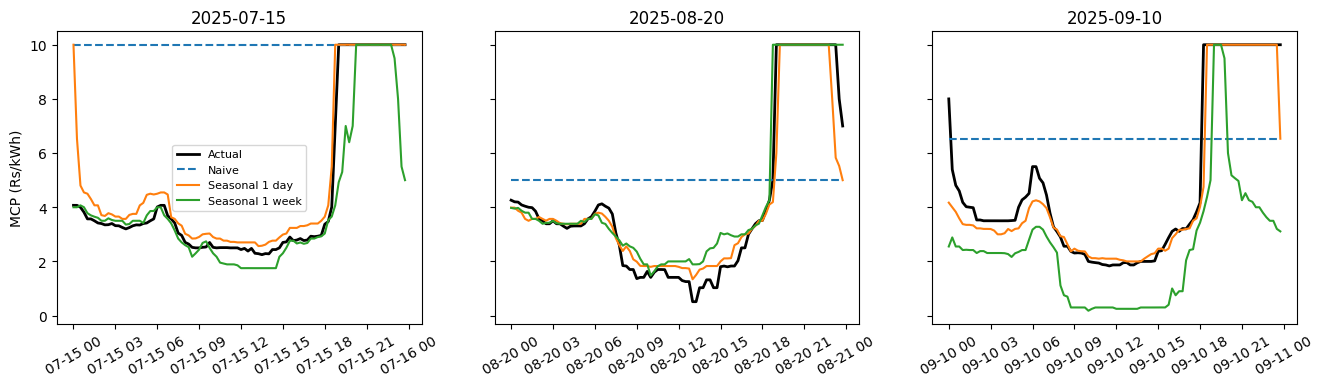

Saved forecasts and metrics.


In [93]:
# ===== PART 2 | CELL 2.4: look at the baselines on three test days + save =====
days = ['2025-07-15', '2025-08-20', '2025-09-10']
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, d in zip(axes, days):
    ax.plot(mcp[d], 'k', lw=2, label='Actual')
    ax.plot(pred_naive[d], '--', label='Naive'); ax.plot(pred_seas_day[d], label='Seasonal 1 day'); ax.plot(pred_seas_week[d], label='Seasonal 1 week')
    ax.set_title(d); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=8)
plt.savefig(f'{OUT}/figures/baselines_three_days.png', dpi=150, bbox_inches='tight'); plt.show()

pd.DataFrame({'actual': mcp, 'naive': pred_naive, 'seasonal_1day': pred_seas_day, 'seasonal_1week': pred_seas_week}).loc[TEST_START:].to_csv(f'{OUT}/forecasts/baselines_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)
print('Saved forecasts and metrics.')

Part 3: stationarity aur ACF/PACF

In [94]:
# ===== PART 3 | CELL 3.1: hourly series for the classical models =====
hourly_all = dam['mcp'].resample('h').mean()
h_train = hourly_all.loc[:TRAIN_END]
print('Hourly series:', hourly_all.shape, '| train part:', h_train.shape)

Hourly series: (24120,) | train part: (19704,)


In [95]:
# ===== PART 3 | CELL 3.2: ADF + KPSS on the TRAINING part only =====
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning
warnings.simplefilter('ignore', InterpolationWarning)   # KPSS p-value is capped by its look-up table; harmless

def stationarity(s, label):
    s = s.dropna()
    adf_p = adfuller(s, autolag='AIC')[1]
    kpss_p = kpss(s, regression='c', nlags='auto')[1]
    if adf_p < 0.05 and kpss_p >= 0.05:   verdict = 'stationary'
    elif adf_p >= 0.05 and kpss_p < 0.05: verdict = 'non-stationary'
    else:                                 verdict = 'mixed (look at plots)'
    return {'series': label, 'n': len(s), 'ADF p': round(adf_p, 4), 'KPSS p': round(kpss_p, 4), 'verdict': verdict}

tests = [stationarity(h_train, 'hourly price (raw)'),
         stationarity(h_train.diff(1), 'diff(1)'),
         stationarity(h_train.diff(24), 'seasonal diff (24h)'),
         stationarity(h_train.diff(24).diff(1), 'seasonal diff (24h) + diff(1)'),
         stationarity(h_train.diff(168), 'weekly seasonal diff (168h)')]
stat_table = pd.DataFrame(tests); print(stat_table.to_string(index=False))
stat_table.to_csv(f'{OUT}/metrics/stationarity_tests.csv', index=False)
print('\nNote: KPSS p-values are capped at 0.01 / 0.10 by the statsmodels look-up table.')

                       series     n  ADF p  KPSS p               verdict
           hourly price (raw) 19704    0.0    0.01 mixed (look at plots)
                      diff(1) 19703    0.0    0.10            stationary
          seasonal diff (24h) 19680    0.0    0.10            stationary
seasonal diff (24h) + diff(1) 19679    0.0    0.10            stationary
  weekly seasonal diff (168h) 19536    0.0    0.10            stationary

Note: KPSS p-values are capped at 0.01 / 0.10 by the statsmodels look-up table.


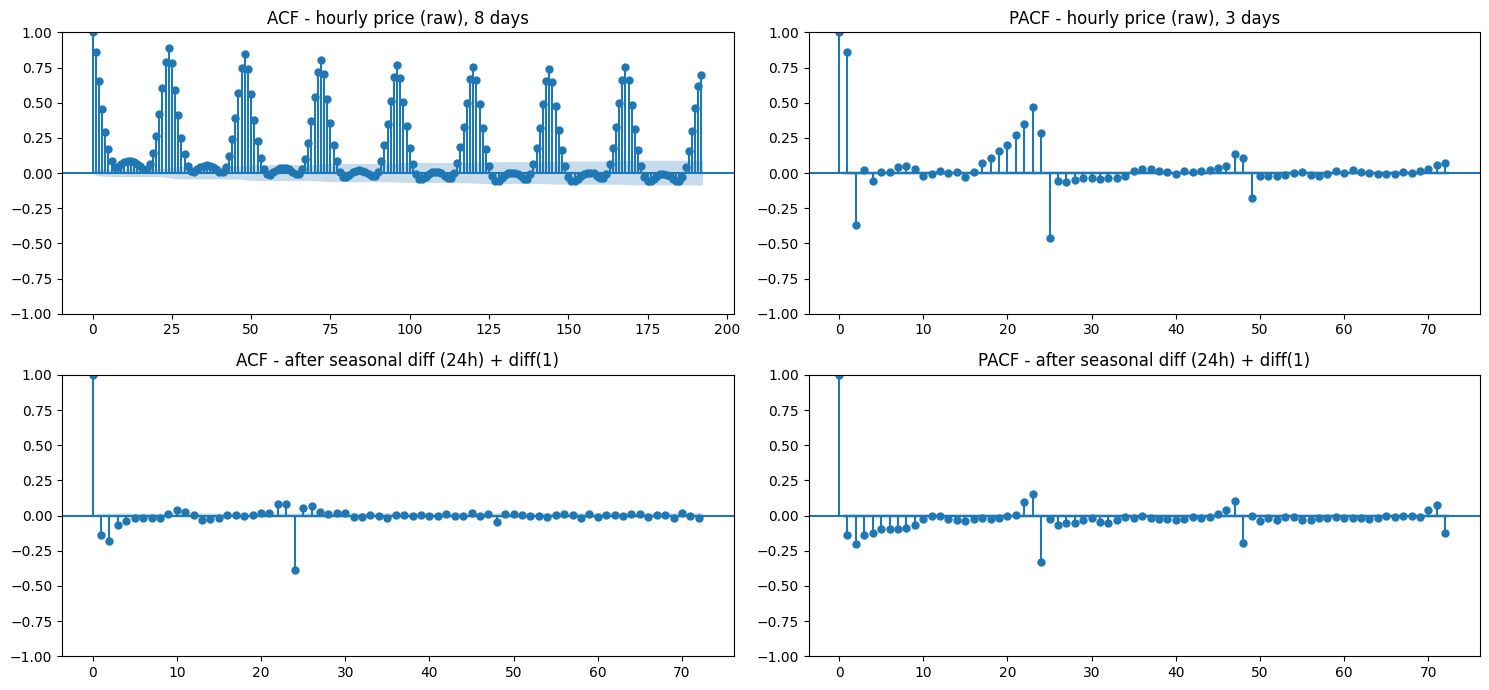

In [96]:
# ===== PART 3 | CELL 3.3: ACF / PACF to guide the model orders =====
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(2, 2, figsize=(15, 7))
raw_h = h_train.dropna(); sd = h_train.diff(24).diff(1).dropna()
plot_acf(raw_h,  lags=192, ax=axes[0, 0]);  axes[0, 0].set_title('ACF - hourly price (raw), 8 days')
plot_pacf(raw_h, lags=72,  ax=axes[0, 1], method='ywm'); axes[0, 1].set_title('PACF - hourly price (raw), 3 days')
plot_acf(sd,  lags=72, ax=axes[1, 0]);  axes[1, 0].set_title('ACF - after seasonal diff (24h) + diff(1)')
plot_pacf(sd, lags=72, ax=axes[1, 1], method='ywm'); axes[1, 1].set_title('PACF - after seasonal diff (24h) + diff(1)')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/acf_pacf.png', dpi=150, bbox_inches='tight'); plt.show()

Part 4: ARIMA

In [97]:
# ===== PART 4 | CELL 4.1: helper + order search (ARIMA, d = 1) =====
import time
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tools.sm_exceptions import ConvergenceWarning, EstimationWarning
for w in (ConvergenceWarning, EstimationWarning): warnings.simplefilter('ignore', w)   # optimiser chatter

VAL_DAYS  = ('2025-04-01', '2025-06-30')
TEST_DAYS = ('2025-07-01', str(dam.index.max().date()))

def rolling_day_ahead(res, series, first_day, last_day):
    """Every day: forecast the next 24 hours using only data up to the previous midnight,
    then feed the day's actual values into the model (parameters stay fixed) and move on."""
    preds = []
    for d in pd.date_range(first_day, last_day, freq='D'):
        fc = res.forecast(24)
        fc.index = pd.date_range(d, periods=24, freq='h')
        preds.append(fc)
        res = res.extend(series.loc[d: d + pd.Timedelta(hours=23)])
    return pd.concat(preds)

def hourly_scores(pred_h):
    y = hourly_all.loc[pred_h.index]
    return np.mean(np.abs(y - pred_h)), np.sqrt(np.mean((y - pred_h) ** 2))

t0 = time.time(); rows = []
for p in range(0, 5):
    for q in range(0, 4):
        try:
            res = ARIMA(h_train, order=(p, 1, q)).fit()
            mae, rmse = hourly_scores(rolling_day_ahead(res, hourly_all, *VAL_DAYS))
            rows.append({'order': f'({p},1,{q})', 'AIC': round(res.aic, 1), 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
        except Exception as e:
            rows.append({'order': f'({p},1,{q})', 'AIC': np.nan, 'val_MAE_h': np.nan, 'val_RMSE_h': np.nan})
arima_grid = pd.DataFrame(rows).sort_values('val_MAE_h').reset_index(drop=True)
print(arima_grid.head(8).to_string(index=False)); print(f'\nSearched {len(rows)} orders in {time.time() - t0:.0f}s')
arima_grid.to_csv(f'{OUT}/metrics/arima_order_search.csv', index=False)

  order     AIC  val_MAE_h  val_RMSE_h
(4,1,2) 63792.2      2.079       2.553
(2,1,3) 63800.2      2.117       2.596
(4,1,3) 63888.4      2.165       2.651
(4,1,1) 64527.2      2.351       2.851
(2,1,2) 64743.1      2.371       2.849
(3,1,1) 64754.5      2.386       2.853
(2,1,1) 64760.9      2.398       2.857
(1,1,3) 65008.3      2.507       2.916

Searched 20 orders in 149s


In [98]:
# ===== PART 4 | CELL 4.2: final ARIMA = best order on validation, refit on train + validation =====
best = arima_grid.iloc[0]['order']; p, d, q = [int(x) for x in best.strip('()').split(',')]
print('Chosen order:', best)

res_tr  = ARIMA(h_train, order=(p, d, q)).fit()                       # fitted on train  -> forecasts validation
res_trv = ARIMA(hourly_all.loc[:VAL_END], order=(p, d, q)).fit()      # fitted on train+val -> forecasts test
pred_val_h  = rolling_day_ahead(res_tr,  hourly_all, *VAL_DAYS)
pred_test_h = rolling_day_ahead(res_trv, hourly_all, *TEST_DAYS)

arima_h = pd.concat([pred_val_h, pred_test_h])
arima_15 = hourly_to_15min(arima_h, dam.index)
evaluate('ARIMA' + best, arima_15)
print(res_trv.summary().tables[1])
print('\nTEST - 15-minute level'); print(results_table('test', '15-min').to_string())
print('\nTEST - hourly level');    print(results_table('test', 'hourly').to_string())
print('\nVALIDATION - hourly level'); print(results_table('val', 'hourly').to_string())

Chosen order: (4,1,2)
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          2.0254      0.007    290.527      0.000       2.012       2.039
ar.L2         -1.4265      0.013   -106.993      0.000      -1.453      -1.400
ar.L3          0.4440      0.013     33.444      0.000       0.418       0.470
ar.L4         -0.1091      0.007    -16.646      0.000      -0.122      -0.096
ma.L1         -1.9106      0.004   -452.575      0.000      -1.919      -1.902
ma.L2          0.9218      0.004    224.762      0.000       0.914       0.930
sigma2         1.4840      0.009    166.076      0.000       1.466       1.502

TEST - 15-minute level
                           MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                         
Seasonal naive (1 day)   0.772  1.495   42.421   25.933  1.106
Seasonal naive (1 week)  0.906  1.595   46.760   29.40

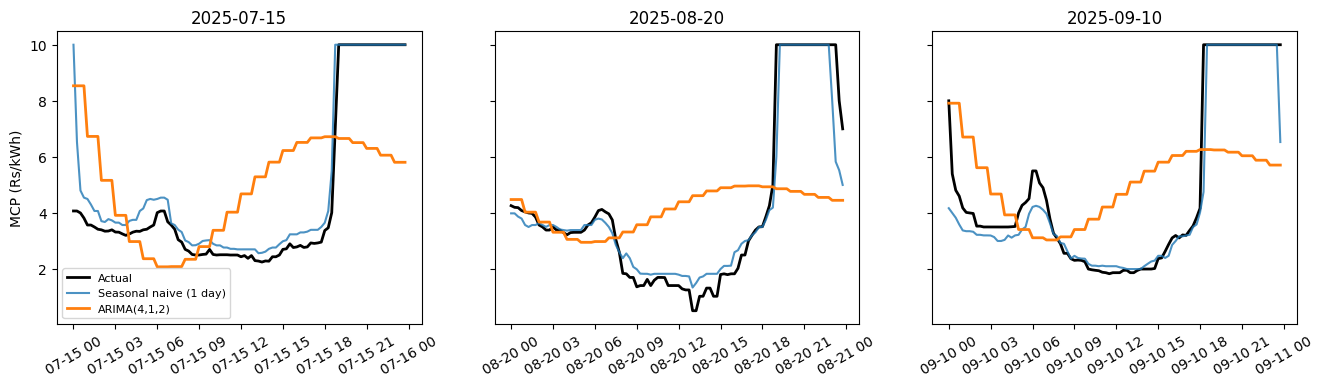

Saved.


In [99]:
# ===== PART 4 | CELL 4.3: plot three test days + save =====
days = ['2025-07-15', '2025-08-20', '2025-09-10']
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8), sharey=True)
for ax, dday in zip(axes, days):
    ax.plot(mcp[dday], 'k', lw=2, label='Actual')
    ax.plot(pred_seas_day[dday], alpha=.8, label='Seasonal naive (1 day)')
    ax.plot(arima_15[dday], label='ARIMA' + best, lw=2)
    ax.set_title(dday); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=8)
plt.savefig(f'{OUT}/figures/arima_three_days.png', dpi=150, bbox_inches='tight'); plt.show()

arima_15.loc[TEST_START:].rename('arima').to_csv(f'{OUT}/forecasts/arima_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)
print('Saved.')

Part 5: SARIMA

In [100]:
# ===== PART 5 | CELL 5.1: SARIMA order search (seasonal period = 24 hours) =====
import gc
FIT_DAYS = 120                                  # SARIMA is fitted on the most recent 120 days (keeps memory and time small)
h_fit = h_train.iloc[-24 * FIT_DAYS:]
CANDIDATES = [((1, 1, 1), (0, 1, 1, 24)), ((2, 1, 1), (0, 1, 1, 24)), ((2, 1, 2), (0, 1, 1, 24)),
              ((3, 1, 2), (0, 1, 1, 24)), ((2, 0, 2), (0, 1, 1, 24)), ((1, 1, 1), (1, 1, 1, 24))]   # from the ACF/PACF in Part 3
t0 = time.time(); rows = []
for order, sorder in CANDIDATES:
    try:
        res = ARIMA(h_fit, order=order, seasonal_order=sorder).fit()
        mae, rmse = hourly_scores(rolling_day_ahead(res, hourly_all, *VAL_DAYS))
        rows.append({'order': str(order) + str(sorder), 'AIC': round(res.aic, 1), 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
        del res; gc.collect()
        print(f'  done {order}{sorder}  val MAE {mae:.3f}  ({time.time() - t0:.0f}s so far)')
    except Exception as e:
        print('  failed', order, sorder, str(e)[:60])
sarima_grid = pd.DataFrame(rows).sort_values('val_MAE_h').reset_index(drop=True)
print('\n', sarima_grid.to_string(index=False)); sarima_grid.to_csv(f'{OUT}/metrics/sarima_order_search.csv', index=False)

  done (1, 1, 1)(0, 1, 1, 24)  val MAE 0.965  (10s so far)
  done (2, 1, 1)(0, 1, 1, 24)  val MAE 0.971  (23s so far)
  done (2, 1, 2)(0, 1, 1, 24)  val MAE 0.959  (42s so far)
  done (3, 1, 2)(0, 1, 1, 24)  val MAE 0.981  (65s so far)
  done (2, 0, 2)(0, 1, 1, 24)  val MAE 0.854  (82s so far)
  done (1, 1, 1)(1, 1, 1, 24)  val MAE 0.848  (111s so far)

                  order    AIC  val_MAE_h  val_RMSE_h
(1, 1, 1)(1, 1, 1, 24) 6539.0      0.848       1.317
(2, 0, 2)(0, 1, 1, 24) 6566.5      0.854       1.334
(2, 1, 2)(0, 1, 1, 24) 6604.5      0.959       1.397
(1, 1, 1)(0, 1, 1, 24) 6611.1      0.965       1.402
(2, 1, 1)(0, 1, 1, 24) 6612.9      0.971       1.407
(3, 1, 2)(0, 1, 1, 24) 6603.2      0.981       1.414


In [101]:
# ===== PART 5 | CELL 5.2: final SARIMA (refit on train + validation) =====
best_s = sarima_grid.iloc[0]['order']
order_s, sorder_s = [CANDIDATES[i] for i in range(len(CANDIDATES)) if str(CANDIDATES[i][0]) + str(CANDIDATES[i][1]) == best_s][0]
print('Chosen:', order_s, sorder_s)
res_s_tr  = ARIMA(h_fit, order=order_s, seasonal_order=sorder_s).fit()
res_s_trv = ARIMA(hourly_all.loc[:VAL_END].iloc[-24 * FIT_DAYS:], order=order_s, seasonal_order=sorder_s).fit()
sarima_h  = pd.concat([rolling_day_ahead(res_s_tr, hourly_all, *VAL_DAYS), rolling_day_ahead(res_s_trv, hourly_all, *TEST_DAYS)])
sarima_15 = hourly_to_15min(sarima_h, dam.index)
SARIMA_NAME = 'SARIMA' + str(order_s) + str(sorder_s)
evaluate(SARIMA_NAME, sarima_15)
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())

Chosen: (1, 1, 1) (1, 1, 1, 24)

TEST - hourly level
                                MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                              
Seasonal naive (1 day)        0.765  1.424   39.768   25.640  1.114
Seasonal naive (1 week)       0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)  0.968  1.401   46.236   34.097  1.410
ARIMA(4,1,2)                  2.065  2.641  118.241   55.479  3.009
Naive (last value)            3.070  3.985  178.250   63.551  4.473


In [102]:
# ===== PART 5 | CELL 5.3: save =====
sarima_15.loc[TEST_START:].rename('sarima').to_csv(f'{OUT}/forecasts/sarima_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)

Part 6: Holt-Winters

In [103]:
# ===== PART 6 | CELL 6.1: Holt-Winters (re-estimated every day on the last 28 days) =====
from statsmodels.tsa.holtwinters import ExponentialSmoothing
HW_CONFIGS = {'HW add-trend(damped) + add-season': dict(trend='add', damped_trend=True, seasonal='add'),
              'HW no-trend + add-season':          dict(trend=None, seasonal='add'),
              'HW add-trend(damped) + mul-season': dict(trend='add', damped_trend=True, seasonal='mul')}

def hw_day_ahead(series, first_day, last_day, cfg, window_days=28):
    preds = []
    for d in pd.date_range(first_day, last_day, freq='D'):
        hist = series.loc[d - pd.Timedelta(days=window_days): d - pd.Timedelta(hours=1)]      # only past data
        fit = ExponentialSmoothing(hist, seasonal_periods=24, initialization_method='estimated', **cfg).fit()
        fc = fit.forecast(24); fc.index = pd.date_range(d, periods=24, freq='h')
        preds.append(fc)
    return pd.concat(preds)

t0 = time.time(); hw_rows = []; hw_val = {}
for name, cfg in HW_CONFIGS.items():
    pv = hw_day_ahead(hourly_all, *VAL_DAYS, cfg); hw_val[name] = pv
    mae, rmse = hourly_scores(pv); hw_rows.append({'config': name, 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
    print(f'  done {name}  val MAE {mae:.3f}  ({time.time() - t0:.0f}s so far)')
hw_grid = pd.DataFrame(hw_rows).sort_values('val_MAE_h').reset_index(drop=True); print('\n', hw_grid.to_string(index=False))
hw_grid.to_csv(f'{OUT}/metrics/holtwinters_config_search.csv', index=False)

  done HW add-trend(damped) + add-season  val MAE 1.612  (28s so far)
  done HW no-trend + add-season  val MAE 1.617  (35s so far)
  done HW add-trend(damped) + mul-season  val MAE 1.118  (62s so far)

                            config  val_MAE_h  val_RMSE_h
HW add-trend(damped) + mul-season      1.118       1.641
HW add-trend(damped) + add-season      1.612       2.092
         HW no-trend + add-season      1.617       2.098


In [104]:
# ===== PART 6 | CELL 6.2: final Holt-Winters on val + test =====
best_hw = hw_grid.iloc[0]['config']
hw_h  = pd.concat([hw_val[best_hw], hw_day_ahead(hourly_all, *TEST_DAYS, HW_CONFIGS[best_hw])])
hw_15 = hourly_to_15min(hw_h, dam.index)
evaluate(best_hw, hw_15)
print('\nChosen:', best_hw); print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
hw_15.loc[TEST_START:].rename('holt_winters').to_csv(f'{OUT}/forecasts/holtwinters_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)


Chosen: HW add-trend(damped) + mul-season

TEST - hourly level
                                     MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                   
Seasonal naive (1 day)             0.765  1.424   39.768   25.640  1.114
Seasonal naive (1 week)            0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)       0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season  1.117  1.595   51.220   34.530  1.627
ARIMA(4,1,2)                       2.065  2.641  118.241   55.479  3.009
Naive (last value)                 3.070  3.985  178.250   63.551  4.473


Part B

In [105]:
# ===== PART 6B | CELL 6B.1: seasonal decomposition forecast - choose additive or multiplicative on validation =====
from statsmodels.tsa.seasonal import seasonal_decompose
CEIL = 10.0
def decomp_day_ahead(series, first_day, last_day, model, window_days=28):
    """Every day: decompose the previous `window_days` days (period 24 h); forecast the next 24 h as level + seasonal (additive) or level x seasonal (multiplicative)."""
    preds = []
    for d in pd.date_range(first_day, last_day, freq='D'):
        hist = series.loc[d - pd.Timedelta(days=window_days): d - pd.Timedelta(hours=1)]              # only past data
        dec = seasonal_decompose(hist, model=model, period=24, extrapolate_trend='freq')
        seas, level = dec.seasonal.iloc[-24:].values, dec.trend.iloc[-24:].mean()                    # last 24 values = hours 00..23 of yesterday
        fc = level + seas if model == 'additive' else level * seas
        preds.append(pd.Series(np.clip(fc, 0.0, CEIL), index=pd.date_range(d, periods=24, freq='h')))
    return pd.concat(preds)

rows = []; val_preds = {}
for model in ('additive', 'multiplicative'):
    for w in (14, 28):
        pv = decomp_day_ahead(hourly_all, *VAL_DAYS, model, w); val_preds[(model, w)] = pv
        mae, rmse = hourly_scores(pv); rows.append({'model': model, 'window_days': w, 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
decomp_grid = pd.DataFrame(rows).sort_values('val_MAE_h').reset_index(drop=True); print(decomp_grid.to_string(index=False))
decomp_grid.to_csv(f'{OUT}/metrics/decomposition_config_search.csv', index=False)

         model  window_days  val_MAE_h  val_RMSE_h
multiplicative           14      0.920       1.357
multiplicative           28      0.972       1.402
      additive           14      1.087       1.463
      additive           28      1.108       1.466


In [106]:
# ===== PART 6B | CELL 6B.2: final decomposition model on validation + test =====
bm, bw = decomp_grid.iloc[0]['model'], int(decomp_grid.iloc[0]['window_days'])
DECOMP_NAME = f'Decomposition ({bm}, {bw}d window)'
decomp_h  = pd.concat([val_preds[(bm, bw)], decomp_day_ahead(hourly_all, *TEST_DAYS, bm, bw)])
decomp_15 = hourly_to_15min(decomp_h, dam.index)
evaluate(DECOMP_NAME, decomp_15)
print('Chosen:', DECOMP_NAME); print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
decomp_15.loc[TEST_START:].rename('decomposition').to_csv(f'{OUT}/forecasts/decomposition_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)

Chosen: Decomposition (multiplicative, 14d window)

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season           1.117  1.595   51.220   34.530  1.627
ARIMA(4,1,2)                                2.065  2.641  118.241   55.479  3.009
Naive (last value)                          3.070  3.985  178.250   63.551  4.473


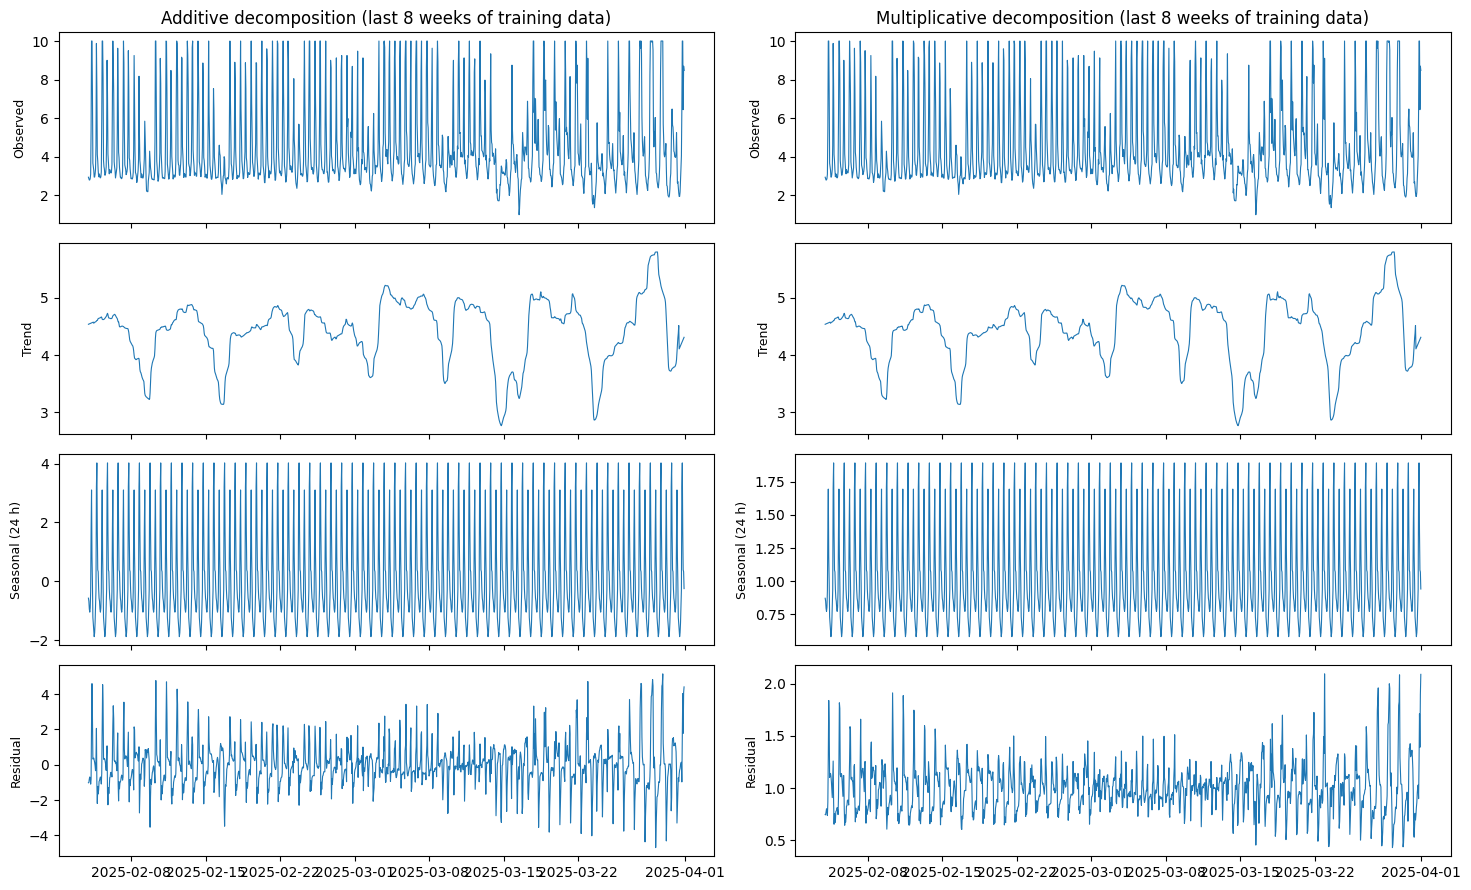

Residual std in Rs/kWh over these 8 weeks: additive 1.255 | multiplicative 1.209


In [107]:
# ===== PART 6B | CELL 6B.3: additive vs multiplicative decomposition of the same 8 training weeks (which fits the data better?) =====
seg = h_train.iloc[-24 * 56:]
fig, axes = plt.subplots(4, 2, figsize=(15, 9), sharex=True)
for j, model in enumerate(('additive', 'multiplicative')):
    dec = seasonal_decompose(seg, model=model, period=24, extrapolate_trend='freq')
    for i, (s, t) in enumerate([(seg, 'Observed'), (dec.trend, 'Trend'), (dec.seasonal, 'Seasonal (24 h)'), (dec.resid, 'Residual')]):
        axes[i, j].plot(s, lw=.8); axes[i, j].set_ylabel(t, fontsize=9)
    axes[0, j].set_title(f'{model.capitalize()} decomposition (last 8 weeks of training data)')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase2_decomposition_add_vs_mul.png', dpi=140, bbox_inches='tight'); plt.show()
add_res = seasonal_decompose(seg, model='additive', period=24, extrapolate_trend='freq').resid.dropna()
mul_res = seasonal_decompose(seg, model='multiplicative', period=24, extrapolate_trend='freq')
mul_resid_price = (seg - mul_res.trend * mul_res.seasonal).dropna()                         # multiplicative residual expressed in Rs/kWh, comparable with the additive one
print(f'Residual std in Rs/kWh over these 8 weeks: additive {add_res.std():.3f} | multiplicative {mul_resid_price.std():.3f}')

Part 7: comparison, plots, residuals

In [108]:
# ===== PART 7 | CELL 7.1: final comparison tables =====
CLASSICAL = [n for n in pd.DataFrame(RESULTS)['model'].unique() if n.startswith(('ARIMA', 'SARIMA', 'HW'))]
print('TEST - hourly level (24 forecasts per day)');      tab_h = results_table('test', 'hourly');  print(tab_h.to_string())
print('\nTEST - 15-minute level (96 blocks per day)');    tab_15 = results_table('test', '15-min'); print(tab_15.to_string())
print('\nVALIDATION - hourly level');                      print(results_table('val', 'hourly').to_string())

ref = tab_h.loc['Seasonal naive (1 day)']
gain = pd.DataFrame({'MAE vs seasonal-naive (%)': (ref['MAE'] - tab_h['MAE']) / ref['MAE'] * 100,
                     'RMSE vs seasonal-naive (%)': (ref['RMSE'] - tab_h['RMSE']) / ref['RMSE'] * 100}).round(1)
print('\nImprovement over the seasonal-naive (1 day) benchmark (positive = better):'); print(gain.loc[CLASSICAL].to_string())
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/phase2_final_results.csv', index=False)

TEST - hourly level (24 forecasts per day)
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season           1.117  1.595   51.220   34.530  1.627
ARIMA(4,1,2)                                2.065  2.641  118.241   55.479  3.009
Naive (last value)                          3.070  3.985  178.250   63.551  4.473

TEST - 15-minute level (96 blocks per day)
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
Seasonal na

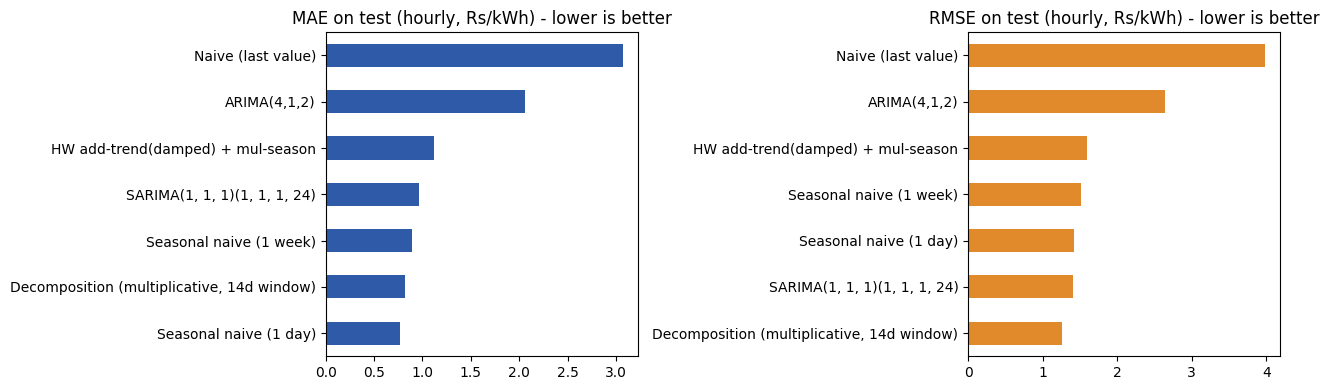

In [109]:
# ===== PART 7 | CELL 7.2: bar chart =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, col, c in zip(axes, ['MAE', 'RMSE'], ['#2f5aa8', '#e08a2c']):
    tab_h[col].sort_values().plot.barh(ax=ax, color=c); ax.set_title(f'{col} on test (hourly, Rs/kWh) - lower is better'); ax.set_ylabel('')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase2_comparison_bars.png', dpi=150, bbox_inches='tight'); plt.show()

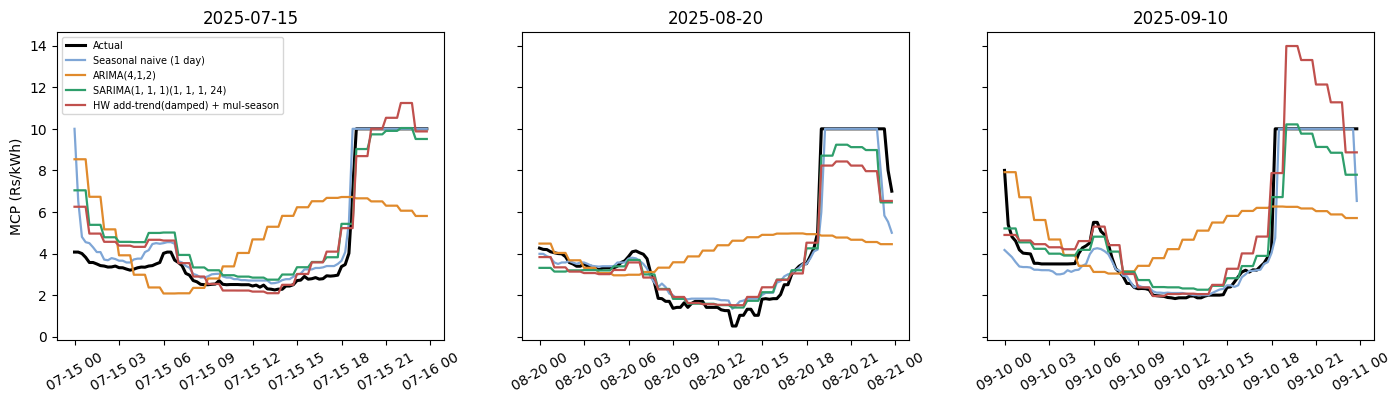

In [110]:
# ===== PART 7 | CELL 7.3: forecasts on three test days, all models =====
PRED15 = {'Seasonal naive (1 day)': pred_seas_day, 'ARIMA' + best: arima_15, SARIMA_NAME: sarima_15, best_hw: hw_15}
days = ['2025-07-15', '2025-08-20', '2025-09-10']
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, dday in zip(axes, days):
    ax.plot(mcp[dday], 'k', lw=2.2, label='Actual')
    for (nm, pr), c in zip(PRED15.items(), ['#7fa6d6', '#e08a2c', '#2e9e6b', '#c0504d']):
        ax.plot(pr[dday], lw=1.6, color=c, label=nm)
    ax.set_title(dday); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=7)
plt.savefig(f'{OUT}/figures/phase2_forecasts_three_days.png', dpi=150, bbox_inches='tight'); plt.show()

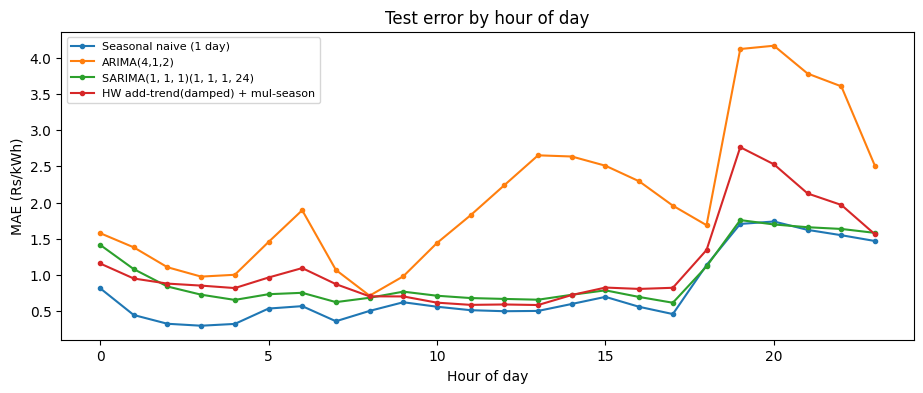

In [111]:
# ===== PART 7 | CELL 7.4: where do the models fail? error by hour of day (test, hourly) =====
yh = hourly(test['mcp'])
fig, ax = plt.subplots(figsize=(11, 4))
for nm, pr in PRED15.items():
    err = (yh - hourly(pr.reindex(test.index))).abs()
    ax.plot(err.groupby(err.index.hour).mean(), marker='o', ms=3, label=nm)
ax.set_xlabel('Hour of day'); ax.set_ylabel('MAE (Rs/kWh)'); ax.set_title('Test error by hour of day'); ax.legend(fontsize=8)
plt.savefig(f'{OUT}/figures/phase2_error_by_hour.png', dpi=150, bbox_inches='tight'); plt.show()

Best classical model (test RMSE): SARIMA(1, 1, 1)(1, 1, 1, 24)


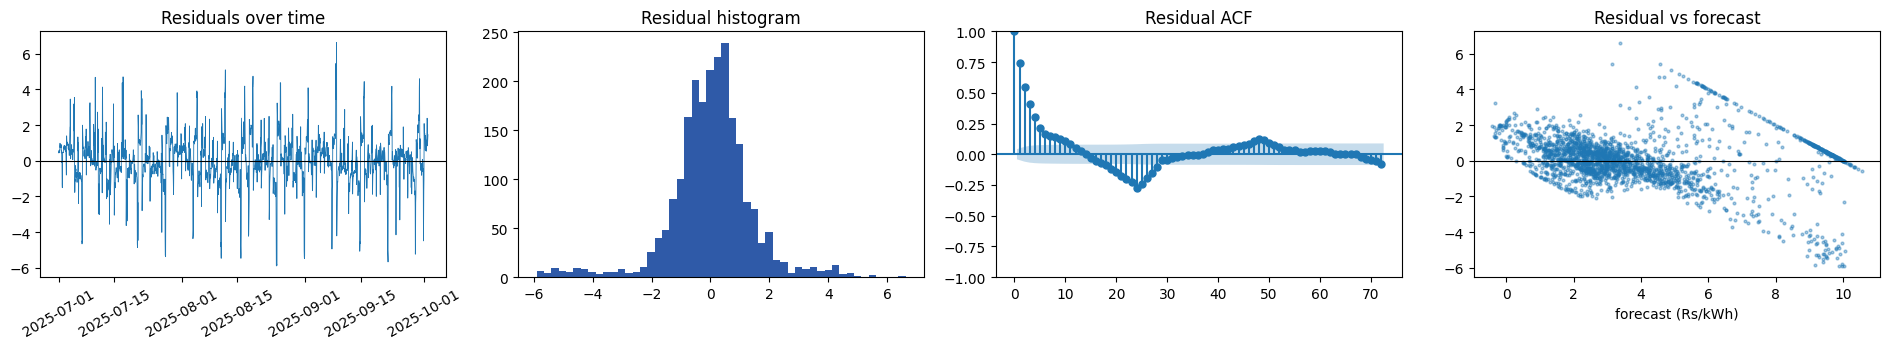

Residual mean 0.035 | std 1.401 | skew -0.49 | Ljung-Box(24) p = 0.0000


In [112]:
# ===== PART 7 | CELL 7.5: residual diagnostics for the best classical model (lowest test RMSE) =====
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
best_cls = tab_h.loc[CLASSICAL, 'RMSE'].idxmin(); print('Best classical model (test RMSE):', best_cls)
resid = (yh - hourly(PRED15[best_cls].reindex(test.index))).dropna()
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
axes[0].plot(resid, lw=.6); axes[0].axhline(0, color='k', lw=.8); axes[0].set_title('Residuals over time'); axes[0].tick_params(axis='x', rotation=30)
axes[1].hist(resid, bins=50, color='#2f5aa8'); axes[1].set_title('Residual histogram')
plot_acf(resid, lags=72, ax=axes[2]); axes[2].set_title('Residual ACF')
axes[3].scatter(hourly(PRED15[best_cls].reindex(test.index)).reindex(resid.index), resid, s=4, alpha=.4); axes[3].axhline(0, color='k', lw=.8)
axes[3].set_title('Residual vs forecast'); axes[3].set_xlabel('forecast (Rs/kWh)')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase2_residuals.png', dpi=150, bbox_inches='tight'); plt.show()
lb = acorr_ljungbox(resid, lags=[24], return_df=True)
print(f'Residual mean {resid.mean():.3f} | std {resid.std():.3f} | skew {resid.skew():.2f} | Ljung-Box(24) p = {lb["lb_pvalue"].iloc[0]:.4f}')

In [113]:
# ===== OPTIONAL | MAPE split: how much of the MAPE comes from very cheap hours? =====
yh = hourly(test['mcp']); low = yh < 1.0
rows = {}
for nm, pr in PRED15.items():
    ph = hourly(pr.reindex(test.index)); ape = (yh - ph).abs() / yh
    rows[nm] = {'MAPE all %': ape.mean() * 100, 'MAPE hours >= Rs1 %': ape[~low].mean() * 100, 'median APE %': ape.median() * 100}
print(f'Hours with actual price < Rs 1: {int(low.sum())} of {len(yh)}')
print(pd.DataFrame(rows).T.round(1).to_string())

Hours with actual price < Rs 1: 122 of 2232
                                   MAPE all %  MAPE hours >= Rs1 %  median APE %
Seasonal naive (1 day)                   39.8                 20.6          11.5
ARIMA(4,1,2)                            118.2                 57.3          44.8
SARIMA(1, 1, 1)(1, 1, 1, 24)             46.2                 28.0          21.3
HW add-trend(damped) + mul-season        51.2                 29.3          27.3


In [114]:
# ===== PART 8 | CELL 8.1: Milestone 2 wrap-up (no new model - just save and list everything) =====
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/phase2_final_results.csv', index=False)
print('Models scored so far:', sorted(pd.DataFrame(RESULTS)['model'].unique()))
for sub in ['data', 'figures', 'forecasts', 'metrics']:
    print(f'\n{sub}/'); print('  ' + '\n  '.join(sorted(os.listdir(f'{OUT}/{sub}'))))

Models scored so far: ['ARIMA(4,1,2)', 'Decomposition (multiplicative, 14d window)', 'HW add-trend(damped) + mul-season', 'Naive (last value)', 'SARIMA(1, 1, 1)(1, 1, 1, 24)', 'Seasonal naive (1 day)', 'Seasonal naive (1 week)']

data/
  autots_best_template.csv
  ceiling_classifier.json
  dam_clean.csv
  dam_features.csv
  dam_features_v2.csv
  gru_final.keras
  lstm_final.keras
  model_card.json
  xgboost_deploy.json
  xgboost_tuned.json

figures/
  acf_pacf.png
  arima_three_days.png
  baselines_three_days.png
  final_model_comparison.png
  phase2_comparison_bars.png
  phase2_decomposition_add_vs_mul.png
  phase2_error_by_hour.png
  phase2_forecasts_three_days.png
  phase2_residuals.png
  phase3_buyer_savings_A.png
  phase3_buyer_savings_B.png
  phase3_ceiling_risk.png
  phase3_cheapest_hours.png
  phase3_error_by_regime.png
  phase3_final_comparison.png
  phase3_prediction_intervals.png
  phase3_rolling_origin.png
  phase3_shap_dependence.png
  phase3_shap_families.png
  phase3_sha

Part 9: features

In [115]:
# ===== PART 9 | CELL 9.1: day-ahead feature table (our own dam_features) =====
# Rule: for a block on day D, use ONLY information available at D-1 23:45. So same-block lags start at 96 (yesterday), never 1 or 4.
CEIL = 10.0                                                      # current price ceiling (Rs/kWh) - a market rule known in advance
idx = dam.index
f = pd.DataFrame(index=idx); f['mcp'] = dam['mcp']

for k in (96, 192, 288, 672):                                    # same block 1, 2, 3 and 7 days ago
    f[f'mcp_lag{k}'] = dam['mcp'].shift(k)
same_block = pd.concat([dam['mcp'].shift(96 * i) for i in range(1, 8)], axis=1)
f['sameblock_mean7'], f['sameblock_std7'], f['sameblock_max7'] = same_block.mean(axis=1), same_block.std(axis=1), same_block.max(axis=1)

day = dam['mcp'].groupby(idx.normalize())
prev = idx.normalize() - pd.Timedelta(days=1)                    # yesterday's date for every block of today
daily = pd.DataFrame({'mean': day.mean(), 'std': day.std(), 'max': day.max(), 'min': day.min(), 'last': day.last(),
                      'cap_share': day.apply(lambda s: (s >= CEIL - 1e-9).mean())})
for c in daily.columns:
    f[f'y_{c}'] = daily[c].reindex(prev).values                  # yesterday's summary
f['y_mean7'] = daily['mean'].rolling(7).mean().reindex(prev).values   # mean of the last 7 days' daily means

for c in ['demand', 'supply', 'mcv']:                            # exchange variables: yesterday only (same-block values are auction outcomes)
    f[f'{c}_lag96'] = dam[c].shift(96)
    f[f'y_{c}_mean'] = dam[c].groupby(idx.normalize()).mean().reindex(prev).values
f['bid_ratio_lag96'] = f['demand_lag96'] / f['supply_lag96']

blk = idx.hour * 4 + idx.minute // 15 + 1                        # block number 1..96 (known in advance)
f['block'], f['hour'], f['dow'], f['month'] = blk, idx.hour, idx.dayofweek, idx.month
f['is_weekend'] = (idx.dayofweek >= 5).astype(int)
f['block_sin'], f['block_cos'] = np.sin(2 * np.pi * blk / 96), np.cos(2 * np.pi * blk / 96)

FEATURES = [c for c in f.columns if c != 'mcp']
f.to_csv(f'{OUT}/data/dam_features.csv', index_label='timestamp')
print('Feature table:', f.shape, '|', len(FEATURES), 'features')
print(FEATURES)
print('Rows with the longest lag missing (first week):', int(f['mcp_lag672'].isna().sum()))

Feature table: (96480, 29) | 28 features
['mcp_lag96', 'mcp_lag192', 'mcp_lag288', 'mcp_lag672', 'sameblock_mean7', 'sameblock_std7', 'sameblock_max7', 'y_mean', 'y_std', 'y_max', 'y_min', 'y_last', 'y_cap_share', 'y_mean7', 'demand_lag96', 'y_demand_mean', 'supply_lag96', 'y_supply_mean', 'mcv_lag96', 'y_mcv_mean', 'bid_ratio_lag96', 'block', 'hour', 'dow', 'month', 'is_weekend', 'block_sin', 'block_cos']
Rows with the longest lag missing (first week): 672


Part 10: XGBoost

In [116]:
# ===== PART 10 | CELL 10.1: XGBoost - data masks and a default (untuned) model =====
import time
import xgboost as xgb
tr_m  = (f.index <= TRAIN_END) & f['mcp_lag672'].notna()
va_m  = (f.index >= VAL_START) & (f.index <= VAL_END)
trv_m = (f.index <= VAL_END) & f['mcp_lag672'].notna()
te_m  = f.index >= TEST_START
Xtr, ytr, Xva, yva, Xtrv, ytrv, Xte = f.loc[tr_m, FEATURES], f.loc[tr_m, 'mcp'], f.loc[va_m, FEATURES], f.loc[va_m, 'mcp'], f.loc[trv_m, FEATURES], f.loc[trv_m, 'mcp'], f.loc[te_m, FEATURES]
clip = lambda a: np.clip(a, 0.0, CEIL)                           # forecasts cannot exceed the known ceiling

def as_series(pred, index): return pd.Series(clip(pred), index=index)
base = xgb.XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=42)
base.fit(Xtr, ytr)
base_pred = pd.concat([as_series(base.predict(Xva), Xva.index), as_series(xgb.XGBRegressor(**base.get_params()).fit(Xtrv, ytrv).predict(Xte), Xte.index)])
evaluate('XGBoost (default)', base_pred)
print('Default XGBoost - TEST, hourly'); print(results_table('test', 'hourly').to_string())

Default XGBoost - TEST, hourly
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (default)                           0.536  0.865   26.883   17.826  0.781
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season           1.117  1.595   51.220   34.530  1.627
ARIMA(4,1,2)                                2.065  2.641  118.241   55.479  3.009
Naive (last value)                          3.070  3.985  178.250   63.551  4.473


In [117]:
# ===== PART 10 | CELL 10.2: tuning (random search, scored on the VALIDATION period only) =====
rng = np.random.RandomState(42); t0 = time.time(); trials = []
for i in range(20):
    p = dict(max_depth=int(rng.choice([3, 4, 5, 6, 8])), learning_rate=float(rng.choice([0.02, 0.03, 0.05, 0.08])),
             subsample=float(rng.choice([0.6, 0.8, 1.0])), colsample_bytree=float(rng.choice([0.5, 0.7, 0.9, 1.0])),
             min_child_weight=int(rng.choice([1, 5, 10, 30])), reg_lambda=float(rng.choice([0.5, 1, 5, 10])),
             objective=str(rng.choice(['reg:squarederror', 'reg:absoluteerror'])))
    m = xgb.XGBRegressor(n_estimators=1500, early_stopping_rounds=50, eval_metric='mae', tree_method='hist', n_jobs=-1, random_state=42, **p)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
    mae = np.mean(np.abs(yva.values - clip(m.predict(Xva))))
    trials.append({**p, 'best_iter': int(m.best_iteration), 'val_MAE_15min': round(mae, 4)})
    print(f'  trial {i + 1:2d}  val MAE {mae:.4f}  ({time.time() - t0:.0f}s)')
xgb_trials = pd.DataFrame(trials).sort_values('val_MAE_15min').reset_index(drop=True)
print('\nTop 5 settings:'); print(xgb_trials.head(5).to_string(index=False))
xgb_trials.to_csv(f'{OUT}/metrics/xgboost_tuning_trials.csv', index=False)

  trial  1  val MAE 0.6868  (2s)
  trial  2  val MAE 0.6913  (3s)
  trial  3  val MAE 0.6596  (4s)
  trial  4  val MAE 0.6922  (5s)
  trial  5  val MAE 0.6991  (6s)
  trial  6  val MAE 0.6569  (7s)
  trial  7  val MAE 0.6499  (9s)
  trial  8  val MAE 0.6857  (10s)
  trial  9  val MAE 0.6895  (12s)
  trial 10  val MAE 0.6570  (15s)
  trial 11  val MAE 0.7025  (18s)
  trial 12  val MAE 0.6316  (20s)
  trial 13  val MAE 0.6504  (22s)
  trial 14  val MAE 0.6604  (24s)
  trial 15  val MAE 0.6463  (26s)
  trial 16  val MAE 0.6833  (28s)
  trial 17  val MAE 0.6374  (30s)
  trial 18  val MAE 0.7094  (31s)
  trial 19  val MAE 0.6714  (34s)
  trial 20  val MAE 0.6777  (35s)

Top 5 settings:
 max_depth  learning_rate  subsample  colsample_bytree  min_child_weight  reg_lambda         objective  best_iter  val_MAE_15min
         5           0.03        0.6               1.0                 5        10.0 reg:absoluteerror        263         0.6316
         4           0.05        0.6               1

In [118]:
# ===== PART 10 | CELL 10.3: final tuned XGBoost (validation from the train-only model, test from train+val) =====
bp = xgb_trials.iloc[0].to_dict(); n_best = int(bp.pop('best_iter')); bp.pop('val_MAE_15min')
for k in ('max_depth', 'min_child_weight'): bp[k] = int(bp[k])
common = dict(tree_method='hist', n_jobs=-1, random_state=42, **bp)
m_tr  = xgb.XGBRegressor(n_estimators=n_best, **common).fit(Xtr, ytr)
m_trv = xgb.XGBRegressor(n_estimators=int(n_best * 1.15), **common).fit(Xtrv, ytrv)    # a little more data -> a few more trees
xgb_pred = pd.concat([as_series(m_tr.predict(Xva), Xva.index), as_series(m_trv.predict(Xte), Xte.index)])
evaluate('XGBoost (tuned)', xgb_pred)
print('Chosen parameters:', bp, '| trees:', n_best)
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
print('\nTEST - 15-minute level'); print(results_table('test', '15-min').to_string())

Chosen parameters: {'max_depth': 5, 'learning_rate': 0.03, 'subsample': 0.6, 'colsample_bytree': 1.0, 'min_child_weight': 5, 'reg_lambda': 10.0, 'objective': 'reg:absoluteerror'} | trees: 263

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
XGBoost (default)                           0.536  0.865   26.883   17.826  0.781
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season           1.117  1.595   51.220   34.530  1.627
ARIMA(4,1,2)                                2.065

In [119]:
# ===== PART 10 | CELL 10.4: top features + save =====
imp = pd.Series(m_trv.feature_importances_, index=FEATURES).sort_values(ascending=False)
print('\nTop 12 features (gain-based importance):'); print(imp.head(12).round(3).to_string())
xgb_pred.loc[TEST_START:].rename('xgboost').to_csv(f'{OUT}/forecasts/xgboost_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)
m_trv.save_model(f'{OUT}/data/xgboost_tuned.json')


Top 12 features (gain-based importance):
mcp_lag96          0.773
sameblock_mean7    0.048
dow                0.032
bid_ratio_lag96    0.031
mcp_lag192         0.014
block_sin          0.012
supply_lag96       0.011
block              0.011
demand_lag96       0.010
sameblock_max7     0.010
mcp_lag672         0.005
mcp_lag288         0.004


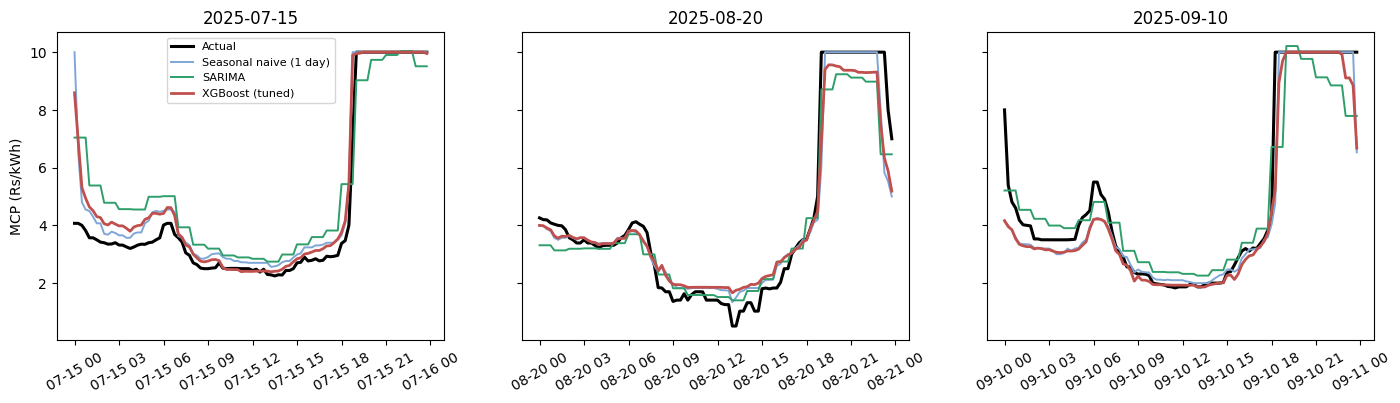

In [120]:
# ===== PART 10 | CELL 10.5: plot three test days =====
days = ['2025-07-15', '2025-08-20', '2025-09-10']
xgb15 = xgb_pred.reindex(dam.index)
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, dday in zip(axes, days):
    ax.plot(mcp[dday], 'k', lw=2.2, label='Actual')
    ax.plot(pred_seas_day[dday], color='#7fa6d6', lw=1.4, label='Seasonal naive (1 day)')
    if 'sarima_15' in globals(): ax.plot(sarima_15[dday], color='#2e9e6b', lw=1.4, label='SARIMA')
    ax.plot(xgb15[dday], color='#c0504d', lw=2, label='XGBoost (tuned)')
    ax.set_title(dday); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=8)
plt.savefig(f'{OUT}/figures/phase3_xgboost_three_days.png', dpi=150, bbox_inches='tight'); plt.show()

Part 11: Prophet

In [121]:
# ===== PART 11 | CELL 11.1: Prophet - imports and helpers =====
import sys, subprocess, logging, time
try:
    from prophet import Prophet
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'prophet'], check=True)   # needs Internet = ON in Kaggle settings
    from prophet import Prophet
for name in ('cmdstanpy', 'prophet'):                              # silence the per-fit INFO messages
    lg = logging.getLogger(name); lg.setLevel(logging.CRITICAL); lg.propagate = False; lg.handlers = [logging.NullHandler()]

CEIL = 10.0
def prophet_predict(history, future_index, cfg):
    """Fit Prophet on the hourly history (ds, y) and predict the given future hours."""
    m = Prophet(daily_seasonality=True, weekly_seasonality=True, yearly_seasonality=cfg['yearly'],
                seasonality_mode=cfg['mode'], changepoint_prior_scale=cfg['cps'])
    m.fit(pd.DataFrame({'ds': history.index, 'y': history.values}))
    yhat = m.predict(pd.DataFrame({'ds': future_index}))['yhat'].values
    return pd.Series(np.clip(yhat, 0.0, CEIL), index=future_index), m

In [122]:
# ===== PART 11 | CELL 11.2: pick the configuration on validation (fit on train once, forecast the whole validation period) =====
cfgs = [dict(mode=m, yearly=y, cps=c) for m in ('additive', 'multiplicative') for y in (False, True) for c in (0.05, 0.3)]
val_hours = pd.date_range(VAL_START, VAL_END, freq='h'); rows = []; t0 = time.time()
for cfg in cfgs:
    pv, _ = prophet_predict(h_train, val_hours, cfg)
    mae, rmse = hourly_scores(pv)
    rows.append({**cfg, 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
    print(f'  {cfg}  val MAE {mae:.3f}  ({time.time() - t0:.0f}s)')
prophet_grid = pd.DataFrame(rows).sort_values('val_MAE_h').reset_index(drop=True)
print('\n', prophet_grid.to_string(index=False)); prophet_grid.to_csv(f'{OUT}/metrics/prophet_config_search.csv', index=False)

  {'mode': 'additive', 'yearly': False, 'cps': 0.05}  val MAE 2.099  (5s)
  {'mode': 'additive', 'yearly': False, 'cps': 0.3}  val MAE 2.208  (12s)
  {'mode': 'additive', 'yearly': True, 'cps': 0.05}  val MAE 2.696  (20s)
  {'mode': 'additive', 'yearly': True, 'cps': 0.3}  val MAE 4.517  (39s)
  {'mode': 'multiplicative', 'yearly': False, 'cps': 0.05}  val MAE 2.099  (47s)
  {'mode': 'multiplicative', 'yearly': False, 'cps': 0.3}  val MAE 2.222  (58s)
  {'mode': 'multiplicative', 'yearly': True, 'cps': 0.05}  val MAE 1.757  (64s)
  {'mode': 'multiplicative', 'yearly': True, 'cps': 0.3}  val MAE 2.087  (88s)

           mode  yearly  cps  val_MAE_h  val_RMSE_h
multiplicative    True 0.05      1.757       2.624
multiplicative    True 0.30      2.087       3.042
      additive   False 0.05      2.099       2.481
multiplicative   False 0.05      2.099       2.478
      additive   False 0.30      2.208       2.545
multiplicative   False 0.30      2.222       2.551
      additive    True 0.0

In [123]:
# ===== PART 11 | CELL 11.3: final Prophet - refit every 7 days on all past data, forecast the next 7 days =====
best_cfg = {k: prophet_grid.iloc[0][k] for k in ('mode', 'yearly', 'cps')}
best_cfg['yearly'] = bool(best_cfg['yearly']); best_cfg['cps'] = float(best_cfg['cps'])
print('Chosen configuration:', best_cfg)

def prophet_rolling(series, first_day, last_day, cfg, step_days=7):
    days = pd.date_range(first_day, last_day, freq='D'); out = []
    for i in range(0, len(days), step_days):
        start, last = days[i], days[min(i + step_days, len(days)) - 1]
        idx = pd.date_range(start, last + pd.Timedelta(hours=23), freq='h')
        pred, _ = prophet_predict(series.loc[:start - pd.Timedelta(hours=1)], idx, cfg)     # only data before 'start'
        out.append(pred)
    return pd.concat(out)

t0 = time.time()
prophet_h = pd.concat([prophet_rolling(hourly_all, *VAL_DAYS, best_cfg), prophet_rolling(hourly_all, *TEST_DAYS, best_cfg)])
prophet_15 = hourly_to_15min(prophet_h, dam.index)
evaluate('Prophet', prophet_15)
print(f'Rolling Prophet done in {time.time() - t0:.0f}s')
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
print('\nVALIDATION - hourly level'); print(results_table('val', 'hourly').to_string())
prophet_15.loc[TEST_START:].rename('prophet').to_csv(f'{OUT}/forecasts/prophet_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)

Chosen configuration: {'mode': 'multiplicative', 'yearly': True, 'cps': 0.05}
Rolling Prophet done in 252s

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
XGBoost (default)                           0.536  0.865   26.883   17.826  0.781
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.968  1.401   46.236   34.097  1.410
HW add-trend(damped) + mul-season           1.117  1.595   51.220   34.530  1.627
Prophet                                     1.781  2.208  106.213   44.930  2.596
ARIMA(4,1,2)                                2.065  2

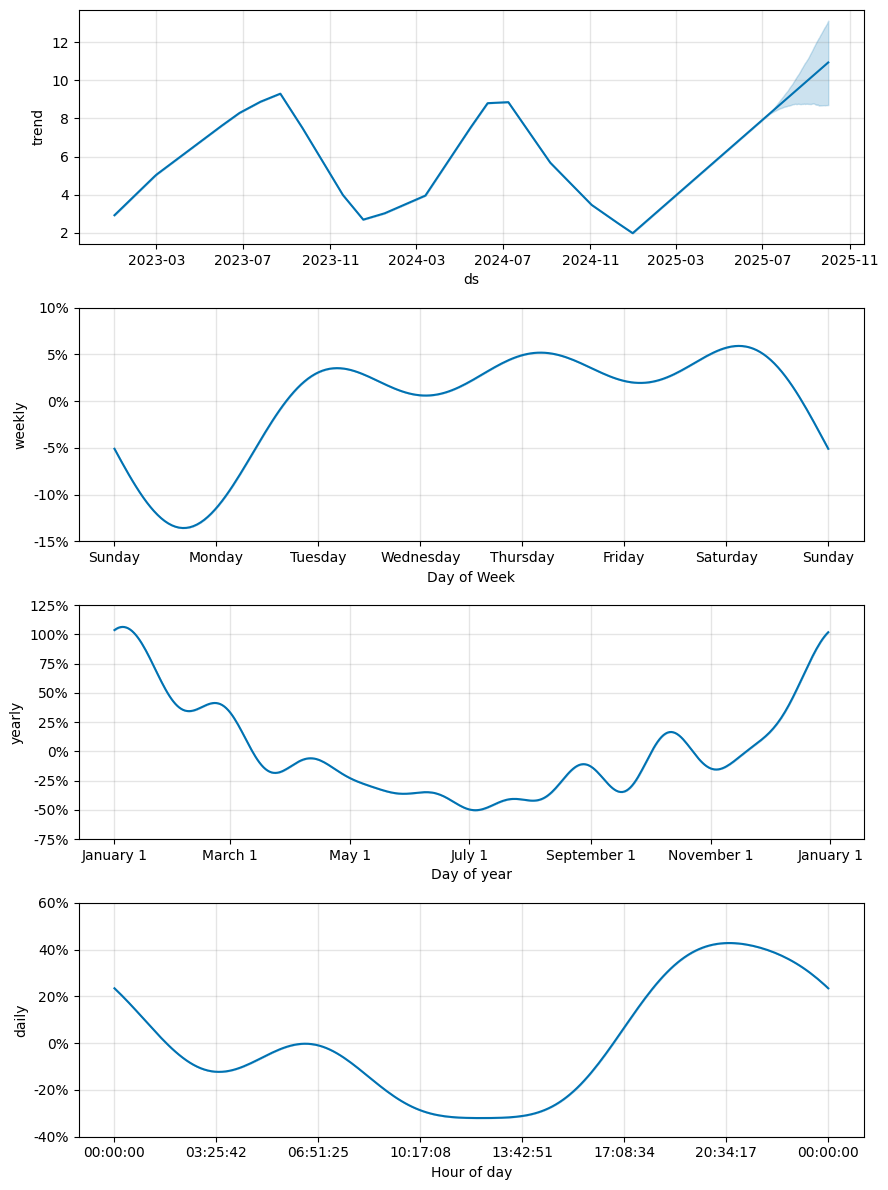

In [124]:
# ===== PART 11 | CELL 11.4: what Prophet learned (trend, weekly, yearly and daily components) =====
_, m_final = prophet_predict(hourly_all.loc[:VAL_END], pd.date_range(TEST_START, periods=24, freq='h'), best_cfg)
fc = m_final.predict(pd.DataFrame({'ds': pd.date_range(hourly_all.index.min(), TEST_DAYS[1] + ' 23:00', freq='h')}))
fig = m_final.plot_components(fc); fig.savefig(f'{OUT}/figures/prophet_components.png', dpi=130, bbox_inches='tight'); plt.show()

Part 12: shared pipeline aur LSTM

In [125]:
# ===== PART 12 | CELL 12.1: deep learning setup =====
import os, time
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
tf.keras.utils.set_random_seed(42)
CEIL = 10.0
print('TensorFlow', tf.__version__, '| GPUs:', tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [126]:
# ===== PART 12 | CELL 12.2: sequence data (one sample = 'last 24 hours in, next 24 hours out') =====
WIN, HOR, STRIDE, SCALE_P = 96, 96, 4, 12.0                       # 96 blocks in, 96 blocks out, a sample every hour
mu, sd = dam.loc[:TRAIN_END, ['demand', 'supply', 'mcv']].mean(), dam.loc[:TRAIN_END, ['demand', 'supply', 'mcv']].std()
A = np.column_stack([dam['mcp'].values / SCALE_P] + [((dam[c] - mu[c]) / sd[c]).values for c in ['demand', 'supply', 'mcv']]).astype('float32')
P = (dam['mcp'].values / SCALE_P).astype('float32')
times, N = dam.index, len(dam)

orig = np.arange(WIN, N - HOR + 1, STRIDE)                        # origin = first block to be forecast
X = np.stack([A[o - WIN:o] for o in orig]); Y = np.stack([P[o:o + HOR] for o in orig])
ot = times[orig]
S = np.column_stack([np.sin(2 * np.pi * (ot.hour * 4 + ot.minute // 15) / 96), np.cos(2 * np.pi * (ot.hour * 4 + ot.minute // 15) / 96),
                     np.sin(2 * np.pi * ot.dayofweek / 7), np.cos(2 * np.pi * ot.dayofweek / 7),
                     np.sin(2 * np.pi * ot.month / 12), np.cos(2 * np.pi * ot.month / 12), (ot.dayofweek >= 5).astype(float)]).astype('float32')

end = times[orig + HOR - 1]                                       # last block of each target window
tr_idx  = np.where(end <= pd.Timestamp(TRAIN_END))[0]
va_idx  = np.where((ot >= pd.Timestamp(VAL_START)) & (end <= pd.Timestamp(VAL_END)))[0]
trv_idx = np.where(end <= pd.Timestamp(VAL_END))[0]
midnight = (ot.hour == 0) & (ot.minute == 0)
va_eval = np.where(midnight & (ot >= pd.Timestamp(VAL_START)) & (end <= pd.Timestamp(VAL_END)))[0]
te_eval = np.where(midnight & (ot >= pd.Timestamp(TEST_START)))[0]
print('X', X.shape, '| train', len(tr_idx), '| val', len(va_idx), '| train+val', len(trv_idx), '| val days', len(va_eval), '| test days', len(te_eval))

X (24073, 96, 4) | train 19657 | val 2161 | train+val 21841 | val days 91 | test days 93


In [127]:
# ===== PART 12 | CELL 12.3: model, training and day-ahead prediction helpers =====
def build_model(kind, units, dropout, lr):
    seq_in, st_in = keras.Input((WIN, 4)), keras.Input((S.shape[1],))
    Rnn = layers.LSTM if kind == 'LSTM' else layers.GRU
    h = Rnn(units, dropout=dropout)(seq_in)
    h = layers.Dense(128, activation='relu')(layers.Concatenate()([h, st_in]))
    m = keras.Model([seq_in, st_in], layers.Dense(HOR, activation='sigmoid')(h))       # sigmoid keeps the output inside 0..SCALE_P
    m.compile(optimizer=keras.optimizers.Adam(lr), loss='mae')
    return m

def predict_days(model, eval_idx):
    p = np.clip(model.predict([X[eval_idx], S[eval_idx]], verbose=0, batch_size=256) * SCALE_P, 0.0, CEIL)
    return pd.concat([pd.Series(p[k], index=times[o:o + HOR]) for k, o in enumerate(orig[eval_idx])])

def val_mae(pred):                                                # 15-minute MAE on the validation days
    y = dam['mcp'].reindex(pred.index); return float(np.mean(np.abs(y - pred)))

CFGS = [dict(units=32, dropout=0.1, lr=1e-3), dict(units=64, dropout=0.1, lr=1e-3),
        dict(units=64, dropout=0.2, lr=3e-3), dict(units=128, dropout=0.2, lr=1e-3)]

def run_rnn(kind, cfgs=CFGS, max_epochs=60):
    t0 = time.time(); rows = []; best = None
    for cfg in cfgs:                                              # 1) tune on validation (train-only model, early stopping)
        keras.utils.set_random_seed(42)
        m = build_model(kind, **cfg)
        h = m.fit([X[tr_idx], S[tr_idx]], Y[tr_idx], validation_data=([X[va_idx], S[va_idx]], Y[va_idx]), epochs=max_epochs, batch_size=128,
                  callbacks=[keras.callbacks.EarlyStopping(patience=8, restore_best_weights=True)], verbose=0)
        pv = predict_days(m, va_eval); mae = val_mae(pv); ep = int(np.argmin(h.history['val_loss']) + 1)
        rows.append({**cfg, 'best_epoch': ep, 'val_MAE_15min': round(mae, 4)})
        print(f'  {kind} {cfg}  best epoch {ep}  val MAE {mae:.4f}  ({time.time() - t0:.0f}s)')
        if best is None or mae < best[0]: best = (mae, cfg, ep, pv)
    grid = pd.DataFrame(rows).sort_values('val_MAE_15min').reset_index(drop=True)
    _, cfg, ep, pv = best
    keras.utils.set_random_seed(42)                               # 2) refit on train+validation for the test period (fixed number of epochs)
    m2 = build_model(kind, **cfg)
    m2.fit([X[trv_idx], S[trv_idx]], Y[trv_idx], epochs=max(3, int(ep * 1.1)), batch_size=128, verbose=0)
    pt = predict_days(m2, te_eval)
    pred = pd.concat([pv, pt]).reindex(dam.index)
    evaluate(kind, pred)
    grid.to_csv(f'{OUT}/metrics/{kind.lower()}_tuning.csv', index=False)
    pred.loc[TEST_START:].rename(kind.lower()).to_csv(f'{OUT}/forecasts/{kind.lower()}_test.csv')
    m2.save(f'{OUT}/data/{kind.lower()}_final.keras')
    print(f'{kind}: chosen {cfg}, epochs {max(3, int(ep * 1.1))}, total {time.time() - t0:.0f}s')
    return pred, grid

In [128]:
# ===== PART 12 | CELL 12.4: train the LSTM =====
lstm_pred, lstm_grid = run_rnn('LSTM')
print('\n', lstm_grid.to_string(index=False))
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())

  LSTM {'units': 32, 'dropout': 0.1, 'lr': 0.001}  best epoch 34  val MAE 0.9534  (53s)
  LSTM {'units': 64, 'dropout': 0.1, 'lr': 0.001}  best epoch 28  val MAE 0.9381  (101s)
  LSTM {'units': 64, 'dropout': 0.2, 'lr': 0.003}  best epoch 17  val MAE 0.9279  (134s)
  LSTM {'units': 128, 'dropout': 0.2, 'lr': 0.001}  best epoch 21  val MAE 0.9223  (177s)
LSTM: chosen {'units': 128, 'dropout': 0.2, 'lr': 0.001}, epochs 23, total 211s

  units  dropout    lr  best_epoch  val_MAE_15min
   128      0.2 0.001          21         0.9223
    64      0.2 0.003          17         0.9279
    64      0.1 0.001          28         0.9381
    32      0.1 0.001          34         0.9534

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
XGBoost (default)                           0.536 

Part 13: GRU

In [129]:
# ===== PART 13 | CELL 13.1: train the GRU (same data, same protocol) =====
gru_pred, gru_grid = run_rnn('GRU')
print('\n', gru_grid.to_string(index=False))
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
print('\nTEST - 15-minute level'); print(results_table('test', '15-min').to_string())

  GRU {'units': 32, 'dropout': 0.1, 'lr': 0.001}  best epoch 60  val MAE 0.8915  (73s)
  GRU {'units': 64, 'dropout': 0.1, 'lr': 0.001}  best epoch 39  val MAE 0.8837  (132s)
  GRU {'units': 64, 'dropout': 0.2, 'lr': 0.003}  best epoch 19  val MAE 0.8969  (166s)
  GRU {'units': 128, 'dropout': 0.2, 'lr': 0.001}  best epoch 20  val MAE 0.8715  (205s)
GRU: chosen {'units': 128, 'dropout': 0.2, 'lr': 0.001}, epochs 22, total 236s

  units  dropout    lr  best_epoch  val_MAE_15min
   128      0.2 0.001          20         0.8715
    64      0.1 0.001          39         0.8837
    32      0.1 0.001          60         0.8915
    64      0.2 0.003          19         0.8969

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
XGBoost (default)                           0.536  0.86

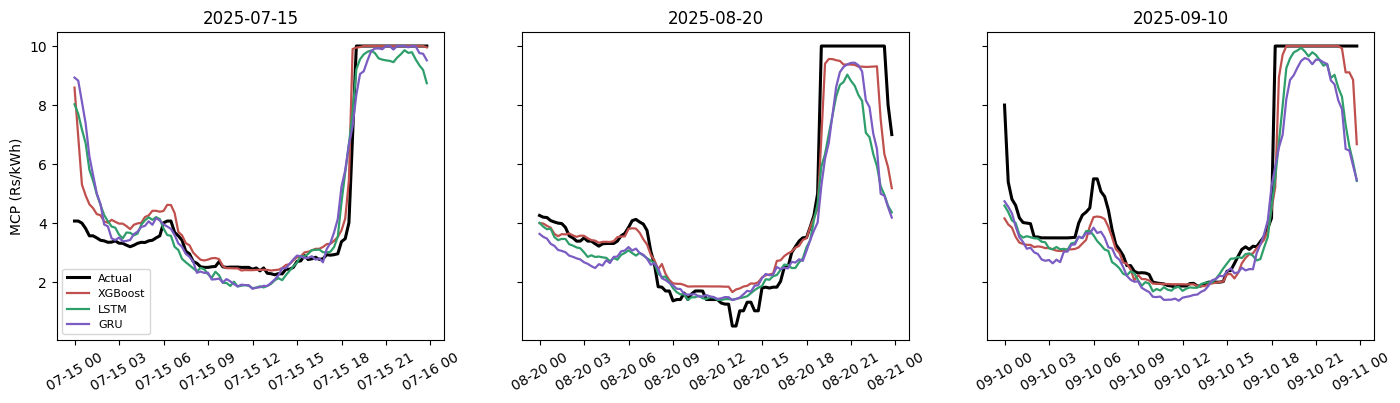

In [130]:
# ===== PART 13 | CELL 13.2: XGBoost vs LSTM vs GRU on three test days =====
days = ['2025-07-15', '2025-08-20', '2025-09-10']
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, dday in zip(axes, days):
    ax.plot(mcp[dday], 'k', lw=2.2, label='Actual')
    ax.plot(xgb_pred.reindex(dam.index)[dday], color='#c0504d', lw=1.6, label='XGBoost')
    ax.plot(lstm_pred[dday], color='#2e9e6b', lw=1.6, label='LSTM')
    ax.plot(gru_pred[dday], color='#7a5cc2', lw=1.6, label='GRU')
    ax.set_title(dday); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=8)
plt.savefig(f'{OUT}/figures/phase3_xgb_lstm_gru_three_days.png', dpi=150, bbox_inches='tight'); plt.show()

Part 14: fair comparison, stability aur walk-forward test

In [131]:
# ===== PART 14 | CELL 14.1: fair comparison - the SAME clipping [0, ceiling] for every model =====
ALL_PREDS = {'Naive (last value)': pred_naive, 'Seasonal naive (1 day)': pred_seas_day, 'Seasonal naive (1 week)': pred_seas_week,
             'ARIMA' + best: arima_15, SARIMA_NAME: sarima_15, best_hw: hw_15, DECOMP_NAME: decomp_15, 'Prophet': prophet_15,
             'XGBoost (tuned)': xgb_pred.reindex(dam.index), 'LSTM': lstm_pred, 'GRU': gru_pred}
CLIPPED = {k: v.clip(0.0, CEIL) for k, v in ALL_PREDS.items()}
names = list(ALL_PREDS)

before = results_table('test', 'hourly').reindex(names)[['MAE', 'RMSE']]
for name, pr in CLIPPED.items(): evaluate(name, pr)
after = results_table('test', 'hourly').reindex(names)[['MAE', 'RMSE']]
effect = pd.concat({'before clipping': before, 'after clipping': after}, axis=1).round(3)
print('Effect of clipping at the ceiling (test, hourly):'); print(effect.to_string())

Effect of clipping at the ceiling (test, hourly):
                                           before clipping        after clipping       
                                                       MAE   RMSE            MAE   RMSE
model                                                                                  
Naive (last value)                                   3.070  3.985          3.070  3.985
Seasonal naive (1 day)                               0.765  1.424          0.765  1.424
Seasonal naive (1 week)                              0.895  1.517          0.895  1.517
ARIMA(4,1,2)                                         2.065  2.641          2.065  2.640
SARIMA(1, 1, 1)(1, 1, 1, 24)                         0.968  1.401          0.963  1.397
HW add-trend(damped) + mul-season                    1.117  1.595          1.052  1.522
Decomposition (multiplicative, 14d window)           0.820  1.256          0.820  1.256
Prophet                                              1.781  2.208     


FINAL - TEST, hourly level (24 forecasts per day)
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
Seasonal naive (1 day)                      0.765  1.424   39.768   25.640  1.114
Decomposition (multiplicative, 14d window)  0.820  1.256   42.401   24.751  1.194
LSTM                                        0.823  1.300   41.766   24.284  1.199
GRU                                         0.830  1.315   40.421   24.402  1.210
Seasonal naive (1 week)                     0.895  1.517   43.920   28.991  1.304
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.963  1.397   45.997   34.083  1.404
HW add-trend(damped) + mul-season           1.052  1.522   50.485   33.962  1.534
Prophet                                     1.781  2.208  106.213   44.930  2.596
ARIMA(4,1,2)                                2.0

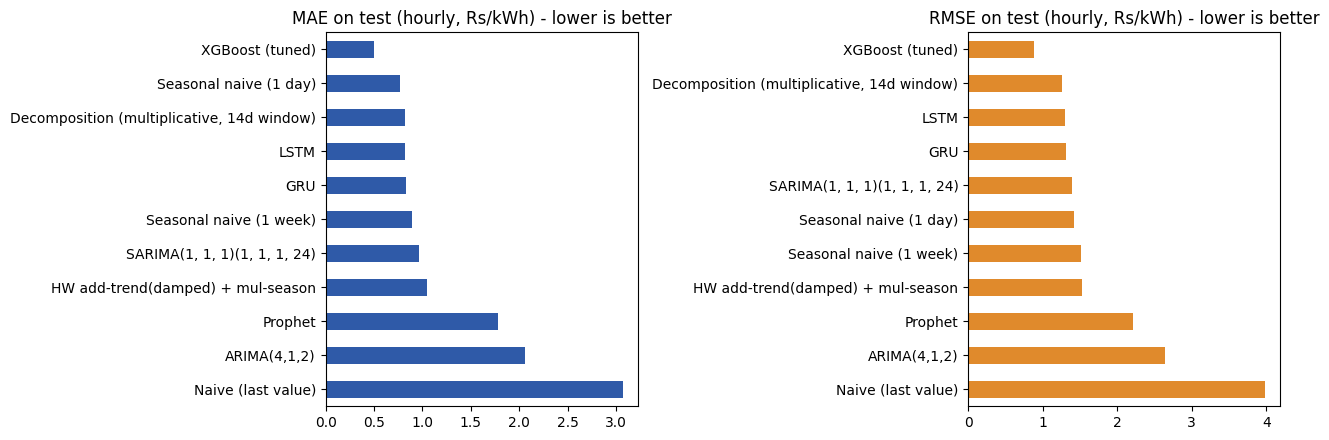

In [132]:
# ===== PART 14 | CELL 14.2: final comparison table =====
tab_h  = results_table('test', 'hourly').reindex(names).sort_values('MAE')
tab_15 = results_table('test', '15-min').reindex(names).sort_values('MAE')
print('\nFINAL - TEST, hourly level (24 forecasts per day)'); print(tab_h.to_string())
print('\nFINAL - TEST, 15-minute level (96 blocks per day)'); print(tab_15.to_string())
ref = tab_h.loc['Seasonal naive (1 day)']
gain = pd.DataFrame({'MAE gain vs seasonal naive (%)': (ref['MAE'] - tab_h['MAE']) / ref['MAE'] * 100,
                     'RMSE gain vs seasonal naive (%)': (ref['RMSE'] - tab_h['RMSE']) / ref['RMSE'] * 100}).round(1)
print('\nGain over the seasonal-naive (1 day) benchmark (positive = better):'); print(gain.to_string())
tab_h.to_csv(f'{OUT}/metrics/final_comparison_hourly.csv'); tab_15.to_csv(f'{OUT}/metrics/final_comparison_15min.csv')
print(f'\nBest by MAE : {tab_h["MAE"].idxmin()}   |   Best by RMSE: {tab_h["RMSE"].idxmin()}')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col, c in zip(axes, ['MAE', 'RMSE'], ['#2f5aa8', '#e08a2c']):
    tab_h[col].sort_values(ascending=False).plot.barh(ax=ax, color=c); ax.set_title(f'{col} on test (hourly, Rs/kWh) - lower is better'); ax.set_ylabel('')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase3_final_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

In [133]:
# ===== PART 14 | CELL 14.3: is the ranking stable? hourly MAE by test month =====
yh = hourly(test['mcp'])
lab = np.where(yh.index.month == 10, 9, yh.index.month)                      # the single day of 1 Oct joins September
MON = {7: 'Jul', 8: 'Aug', 9: 'Sep'}
rows = {}
for name, pr in CLIPPED.items():
    err = (yh - hourly(pr.reindex(test.index))).abs()
    rows[name] = err.groupby(lab).mean().rename(index=MON)
by_month = pd.DataFrame(rows).T.reindex(tab_h.index).round(3)
print('Hourly MAE by test month (models sorted by overall MAE):'); print(by_month.to_string())
by_month.to_csv(f'{OUT}/metrics/mae_by_month.csv')

Hourly MAE by test month (models sorted by overall MAE):
                                              Jul    Aug    Sep
model                                                          
XGBoost (tuned)                             0.498  0.543  0.465
Seasonal naive (1 day)                      0.703  0.847  0.744
Decomposition (multiplicative, 14d window)  0.800  0.838  0.821
LSTM                                        0.792  0.938  0.739
GRU                                         0.744  0.944  0.802
Seasonal naive (1 week)                     0.866  0.831  0.987
SARIMA(1, 1, 1)(1, 1, 1, 24)                0.897  1.070  0.922
HW add-trend(damped) + mul-season           0.881  1.211  1.065
Prophet                                     1.199  2.205  1.940
ARIMA(4,1,2)                                1.971  2.224  1.999
Naive (last value)                          3.577  3.208  2.423


In [134]:
# ===== PART 14 | CELL 14.4: walk-forward test for XGBoost - refit at the start of every test month on ALL earlier data =====
months = [('2025-07-01', '2025-07-31'), ('2025-08-01', '2025-08-31'), ('2025-09-01', str(dam.index.max().date()))]
parts = []
for a, b in months:
    trn = (f.index < a) & f['mcp_lag672'].notna(); tst = (f.index >= a) & (f.index <= b + ' 23:45')
    m = xgb.XGBRegressor(n_estimators=int(n_best * 1.15), **common).fit(f.loc[trn, FEATURES], f.loc[trn, 'mcp'])
    parts.append(pd.Series(np.clip(m.predict(f.loc[tst, FEATURES]), 0.0, CEIL), index=f.index[tst]))
xgb_wf = pd.concat(parts).astype('float64').reindex(dam.index)
xgb_wf.loc[VAL_START:VAL_END] = xgb_pred.reindex(dam.index).loc[VAL_START:VAL_END]       # validation part is not part of this test
evaluate('XGBoost (walk-forward)', xgb_wf)
cmp = results_table('test', 'hourly').reindex(['XGBoost (tuned)', 'XGBoost (walk-forward)', 'Seasonal naive (1 day)'])
print('\nStatic model (trained once on train+val) vs walk-forward (monthly refit) - TEST, hourly'); print(cmp.to_string())
xgb_wf.loc[TEST_START:].rename('xgboost_walkforward').to_csv(f'{OUT}/forecasts/xgboost_walkforward_test.csv')


Static model (trained once on train+val) vs walk-forward (monthly refit) - TEST, hourly
                          MAE   RMSE  MAPE_%  sMAPE_%   MASE
model                                                       
XGBoost (tuned)         0.502  0.877  27.586   17.031  0.732
XGBoost (walk-forward)  0.497  0.876  27.601   16.920  0.724
Seasonal naive (1 day)  0.765  1.424  39.768   25.640  1.114


In [135]:
# ===== PART 14 | CELL 14.5: is the gain real? paired comparison on daily errors (test days) =====
from scipy.stats import wilcoxon
def daily_mae(pr):
    e = (yh - hourly(pr.reindex(test.index))).abs(); return e.groupby(e.index.date).mean()
base_d = daily_mae(CLIPPED['Seasonal naive (1 day)'])
print(f'Paired comparison against Seasonal naive (1 day) over {len(base_d)} test days (daily hourly-MAE):')
for name in ['XGBoost (tuned)', 'GRU', 'LSTM', SARIMA_NAME]:
    d = base_d - daily_mae(CLIPPED[name]); w = wilcoxon(d)
    print(f'  {name:36s} better on {(d > 0).mean() * 100:3.0f}% of days | median daily gain {d.median():+.3f} | Wilcoxon p = {w.pvalue:.4f}')

# ===== PART 14 | CELL 14.6: save =====
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/phase3_all_results.csv', index=False)
print('Saved: final comparison tables, monthly table, walk-forward forecasts, all results.')

Paired comparison against Seasonal naive (1 day) over 93 test days (daily hourly-MAE):
  XGBoost (tuned)                      better on  68% of days | median daily gain +0.045 | Wilcoxon p = 0.0000
  GRU                                  better on  38% of days | median daily gain -0.150 | Wilcoxon p = 0.0864
  LSTM                                 better on  34% of days | median daily gain -0.113 | Wilcoxon p = 0.1038
  SARIMA(1, 1, 1)(1, 1, 1, 24)         better on  18% of days | median daily gain -0.203 | Wilcoxon p = 0.0000
Saved: final comparison tables, monthly table, walk-forward forecasts, all results.


Part 15: volatility, spike aur ceiling-risk classifier

In [136]:
# ===== PART 15 | CELL 15.1: define volatile days and ceiling blocks (used only to EVALUATE, never as model inputs) =====
last_12 = dam.index[dam['mcp'] > 10].max()                                   # the ceiling was 12 until this block, 10 afterwards
ceil_s = pd.Series(np.where(dam.index <= last_12, 12.0, 10.0), index=dam.index)
cap = (dam['mcp'] >= ceil_s - 1e-6)                                          # block priced exactly at the ceiling of its period

yh = hourly(test['mcp'])
yh_all = hourly(dam['mcp'])
dstd = yh_all.groupby(yh_all.index.normalize()).std()                        # intraday spread of each day
VOL_THR = dstd.loc[:TRAIN_END].quantile(0.75)                                # 'volatile' = above the 75th percentile of the TRAIN days
day_flag = (dstd.loc[TEST_START:] > VOL_THR)
vol_h = day_flag.reindex(yh.index.normalize()).values.astype(bool)           # hour-level flag
dmean = yh_all.groupby(yh_all.index.normalize()).mean()
chg = dmean.diff().abs()                                                     # how different is today's average price from yesterday's?
SHIFT_THR = chg.loc[:TRAIN_END].quantile(0.75)                               # 'big change' = above the 75th percentile of TRAIN days
shift_flag = (chg.loc[TEST_START:] > SHIFT_THR)
shift_h = shift_flag.reindex(yh.index.normalize()).values.astype(bool)
cap_hour = (cap.loc[TEST_START:].resample('h').mean() >= 0.5).reindex(yh.index).values
print(f'Volatile-day threshold (daily std of hourly price): {VOL_THR:.2f}')
print(f'Test days: {len(day_flag)} | volatile: {int(day_flag.sum())} | normal: {int((~day_flag).sum())}')
print(f'Big day-to-day change threshold: {SHIFT_THR:.2f} Rs/kWh | test days above it: {int(shift_flag.sum())} | stable days: {int((~shift_flag).sum())}')
print(f'Test blocks at the ceiling: {int(cap.loc[TEST_START:].sum())} ({cap.loc[TEST_START:].mean() * 100:.1f}%) | ceiling hours: {int(cap_hour.sum())} of {len(cap_hour)}')

Volatile-day threshold (daily std of hourly price): 2.85
Test days: 93 | volatile: 37 | normal: 56
Big day-to-day change threshold: 0.84 Rs/kWh | test days above it: 29 | stable days: 64
Test blocks at the ceiling: 1163 (13.0%) | ceiling hours: 308 of 2232



MAE by regime (Rs/kWh)
                                            normal days  volatile days  stable days  big-change days  non-ceiling hours  ceiling hours
model                                                                                                                                 
XGBoost (tuned)                                   0.524          0.469        0.405            0.716              0.462          0.753
Seasonal naive (1 day)                            0.879          0.591        0.429            1.506              0.704          1.146
Decomposition (multiplicative, 14d window)        0.887          0.718        0.625            1.250              0.700          1.564
LSTM                                              0.816          0.834        0.686            1.124              0.646          1.928
GRU                                               0.805          0.867        0.699            1.119              0.643          1.998
Seasonal naive (1 week)        

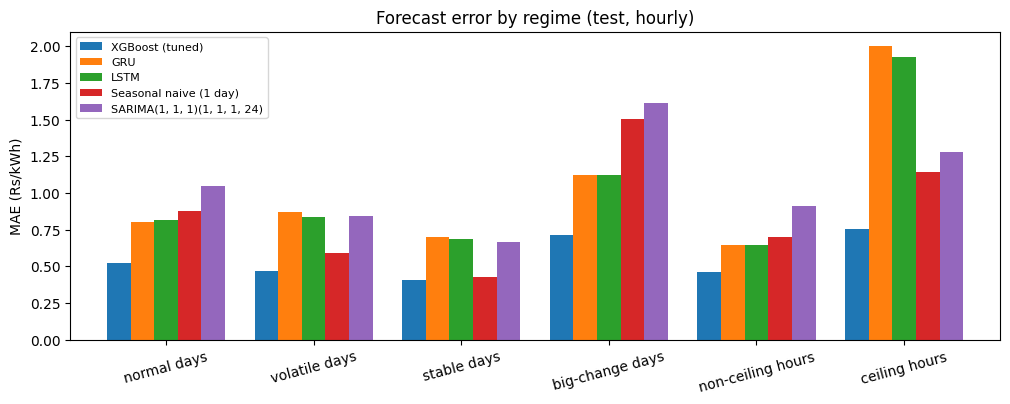

In [137]:
# ===== PART 15 | CELL 15.2: forecast error by regime (hourly level, test) =====
def err_stats(mask, pr):
    e = (yh - hourly(pr.reindex(test.index)))[mask]
    return e.abs().mean(), np.sqrt((e ** 2).mean())
groups = {'normal days': ~vol_h, 'volatile days': vol_h, 'stable days': ~shift_h, 'big-change days': shift_h, 'non-ceiling hours': ~cap_hour, 'ceiling hours': cap_hour}
mae_t = pd.DataFrame({g: {n: err_stats(m, pr)[0] for n, pr in CLIPPED.items()} for g, m in groups.items()})
rmse_t = pd.DataFrame({g: {n: err_stats(m, pr)[1] for n, pr in CLIPPED.items()} for g, m in groups.items()})
order = tab_h.index
print('\nMAE by regime (Rs/kWh)'); print(mae_t.reindex(order).round(3).to_string())
print('\nRMSE by regime (Rs/kWh)'); print(rmse_t.reindex(order).round(3).to_string())
mae_t.reindex(order).round(4).to_csv(f'{OUT}/metrics/mae_by_regime.csv'); rmse_t.reindex(order).round(4).to_csv(f'{OUT}/metrics/rmse_by_regime.csv')

top = ['XGBoost (tuned)', 'GRU', 'LSTM', 'Seasonal naive (1 day)', SARIMA_NAME]
ax = mae_t.loc[top].T.plot.bar(figsize=(12, 4), width=0.8, rot=15)
ax.set_ylabel('MAE (Rs/kWh)'); ax.set_title('Forecast error by regime (test, hourly)'); ax.legend(fontsize=8)
plt.savefig(f'{OUT}/figures/phase3_error_by_regime.png', dpi=150, bbox_inches='tight'); plt.show()

In [138]:
# ===== PART 15 | CELL 15.3: can a price forecast be used as a spike alarm? (alarm = forecast >= 80% of the ceiling) =====
from sklearn.metrics import precision_recall_fscore_support, roc_auc_score, average_precision_score, precision_recall_curve, f1_score
SPIKE_THR = 8.0
y_cap = cap.loc[TEST_START:].values.astype(int)
rows = []
for name, pr in CLIPPED.items():
    flag = pr.reindex(test.index).values >= SPIKE_THR
    p, r, f1, _ = precision_recall_fscore_support(y_cap, flag, average='binary', zero_division=0)
    rows.append({'model': name, 'precision': p, 'recall': r, 'F1': f1})
det = pd.DataFrame(rows).set_index('model').reindex(order).round(3)
print(f'Spike alarm from the price forecast (block level, test; base rate of ceiling blocks = {y_cap.mean() * 100:.1f}%)'); print(det.to_string())

Spike alarm from the price forecast (block level, test; base rate of ceiling blocks = 13.0%)
                                            precision  recall     F1
model                                                               
XGBoost (tuned)                                 0.881   0.861  0.871
Seasonal naive (1 day)                          0.730   0.770  0.750
Decomposition (multiplicative, 14d window)      0.757   0.598  0.668
LSTM                                            0.833   0.590  0.690
GRU                                             0.832   0.572  0.678
Seasonal naive (1 week)                         0.665   0.716  0.690
SARIMA(1, 1, 1)(1, 1, 1, 24)                    0.746   0.731  0.738
HW add-trend(damped) + mul-season               0.786   0.603  0.682
Prophet                                         0.576   0.697  0.631
ARIMA(4,1,2)                                    0.115   0.010  0.019
Naive (last value)                              0.179   0.385  0.245


In [139]:
# ===== PART 15 | CELL 15.4: a dedicated ceiling-risk classifier (same day-ahead features, same split protocol) =====
import xgboost as xgb
tr_c  = (f.index <= TRAIN_END) & f['mcp_lag672'].notna(); va_c = (f.index >= VAL_START) & (f.index <= VAL_END)
trv_c = (f.index <= VAL_END) & f['mcp_lag672'].notna();  te_c = f.index >= TEST_START
lab = cap.reindex(f.index).astype(int)
Xtr, ytr, Xva, yva, Xtrv, ytrv, Xte, yte = (f.loc[tr_c, FEATURES], lab[tr_c], f.loc[va_c, FEATURES], lab[va_c],
                                            f.loc[trv_c, FEATURES], lab[trv_c], f.loc[te_c, FEATURES], lab[te_c])
cp = dict(max_depth=5, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8, min_child_weight=5, tree_method='hist', n_jobs=-1, random_state=42)
clf = xgb.XGBClassifier(n_estimators=1000, early_stopping_rounds=50, eval_metric='logloss', **cp).fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
pva = clf.predict_proba(Xva)[:, 1]
ths = np.arange(0.10, 0.91, 0.05); f1s = [f1_score(yva, pva >= t) for t in ths]; THR_C = float(ths[int(np.argmax(f1s))])   # threshold chosen on VALIDATION
clf2 = xgb.XGBClassifier(n_estimators=int(clf.best_iteration * 1.15) + 1, **cp).fit(Xtrv, ytrv)                              # refit on train+val
pte = clf2.predict_proba(Xte)[:, 1]
print(f'Trees: {clf.best_iteration + 1} | validation F1 {max(f1s):.3f} at threshold {THR_C:.2f}')

def row(name, score, flag):
    p, r, f1, _ = precision_recall_fscore_support(yte, flag, average='binary', zero_division=0)
    return {'method': name, 'ROC AUC': roc_auc_score(yte, score), 'Avg precision': average_precision_score(yte, score), 'precision': p, 'recall': r, 'F1': f1}
xgb_price = CLIPPED['XGBoost (tuned)'].reindex(f.index[te_c]).values
yday = f.loc[te_c, 'mcp_lag96'].values
cmp_c = pd.DataFrame([row('Ceiling-risk classifier (XGBoost)', pte, pte >= THR_C),
                      row('XGBoost price forecast >= 8', xgb_price, xgb_price >= SPIKE_THR),
                      row('Yesterday same block at ceiling', yday, yday >= 9.99)]).set_index('method').round(3)
print(f'\nCeiling blocks on the test set (base rate {yte.mean() * 100:.1f}%):'); print(cmp_c.to_string())
cmp_c.to_csv(f'{OUT}/metrics/ceiling_risk_comparison.csv')
pd.DataFrame({'ceiling_prob': pte, 'actual_ceiling': yte.values}, index=f.index[te_c]).to_csv(f'{OUT}/forecasts/ceiling_risk_test.csv')
clf2.save_model(f'{OUT}/data/ceiling_classifier.json')

Trees: 140 | validation F1 0.832 at threshold 0.50

Ceiling blocks on the test set (base rate 13.0%):
                                   ROC AUC  Avg precision  precision  recall     F1
method                                                                             
Ceiling-risk classifier (XGBoost)    0.990          0.941      0.870   0.872  0.871
XGBoost price forecast >= 8          0.989          0.926      0.881   0.861  0.871
Yesterday same block at ceiling      0.960          0.710      0.747   0.745  0.746


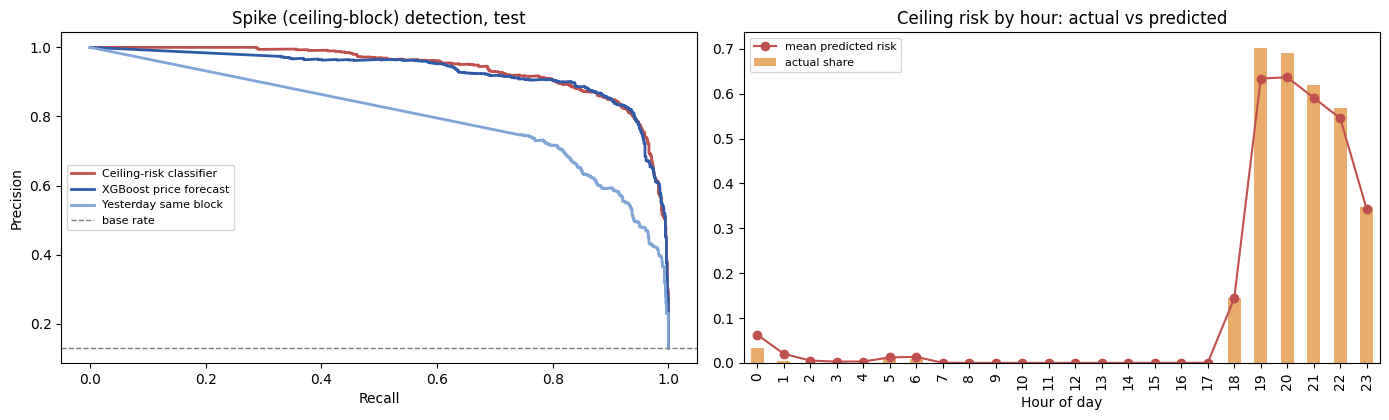

In [140]:
# ===== PART 15 | CELL 15.5: precision-recall curves and risk by hour of day =====
fig, axes = plt.subplots(1, 2, figsize=(14, 4.3))
for lbl, sc, c in [('Ceiling-risk classifier', pte, '#c0504d'), ('XGBoost price forecast', xgb_price, '#2f5aa8'), ('Yesterday same block', yday, '#7fa6d6')]:
    pr_, rc_, _ = precision_recall_curve(yte, sc); axes[0].plot(rc_, pr_, label=lbl, color=c, lw=2)
axes[0].axhline(yte.mean(), color='gray', ls='--', lw=1, label='base rate'); axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Spike (ceiling-block) detection, test'); axes[0].legend(fontsize=8)
hrs = f.index[te_c].hour
by_h = pd.DataFrame({'actual share at ceiling': yte.values, 'mean predicted risk': pte}).groupby(hrs).mean()
by_h['actual share at ceiling'].plot.bar(ax=axes[1], color='#e08a2c', alpha=.7, label='actual share')
axes[1].plot(range(24), by_h['mean predicted risk'].values, color='#c0504d', marker='o', label='mean predicted risk')
axes[1].set_xlabel('Hour of day'); axes[1].set_title('Ceiling risk by hour: actual vs predicted'); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase3_ceiling_risk.png', dpi=150, bbox_inches='tight'); plt.show()

Part 16: SHAP

In [141]:
# ===== PART 16 | CELL 16.1: SHAP values for the tuned XGBoost (explained on the TEST rows) =====
import sys, subprocess
try:
    import shap
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'shap'], check=True)    # needs Internet = ON in Kaggle settings
    import shap
explainer = shap.TreeExplainer(m_trv)                       # m_trv = the tuned model trained on train+validation (Part 10)
sv = explainer(Xte)                                         # one SHAP value per feature per test block
print('SHAP values:', sv.values.shape, '| base value (typical price level): %.2f Rs/kWh' % float(np.ravel(sv.base_values)[0]))
check = np.abs(sv.values.sum(axis=1) + sv.base_values - m_trv.predict(Xte)).max()
print('Check: SHAP values add up to the model output (max difference): %.4f' % check)

SHAP values: (8928, 28) | base value (typical price level): 4.33 Rs/kWh
Check: SHAP values add up to the model output (max difference): 0.0000



Top 15 features by mean |SHAP| (average effect on the forecast, Rs/kWh):
mcp_lag96          1.492
dow                0.257
sameblock_mean7    0.241
bid_ratio_lag96    0.180
mcp_lag192         0.081
supply_lag96       0.056
y_mean7            0.047
mcp_lag672         0.033
block              0.030
y_mcv_mean         0.024
y_min              0.023
y_supply_mean      0.020
y_mean             0.017
demand_lag96       0.012
y_last             0.011


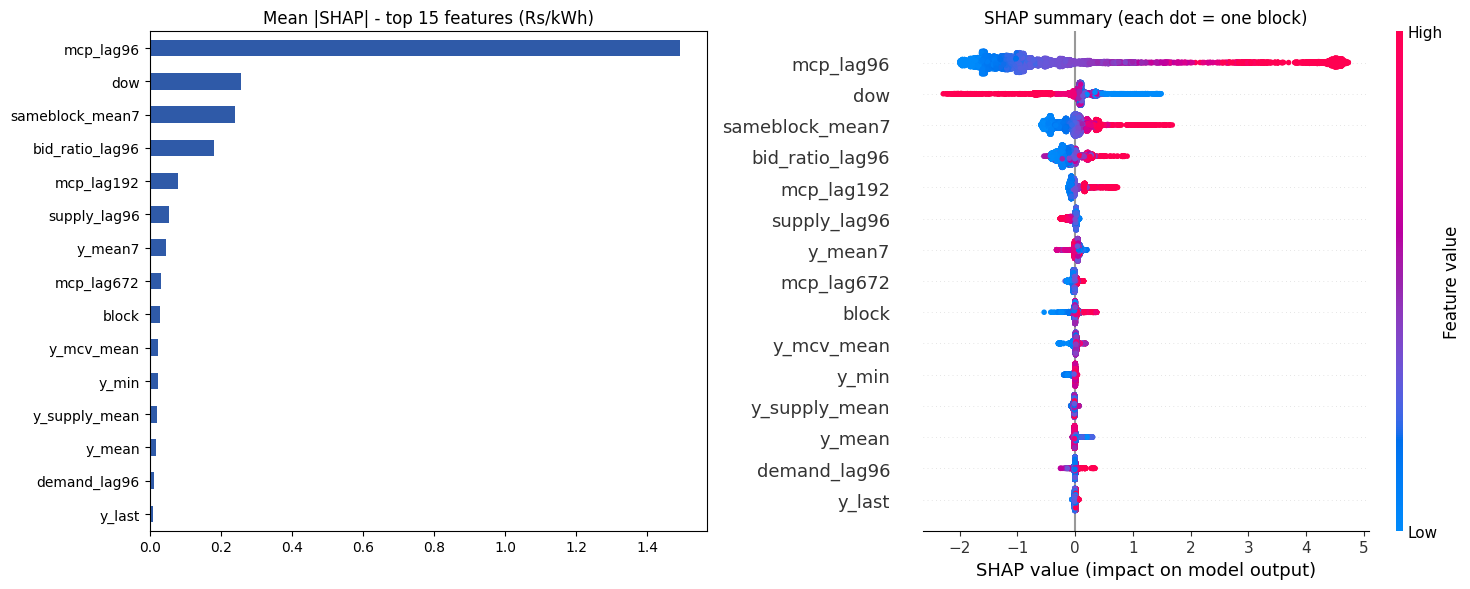

In [142]:
# ===== PART 16 | CELL 16.2: which features matter most? =====
imp = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
print('\nTop 15 features by mean |SHAP| (average effect on the forecast, Rs/kWh):'); print(imp.head(15).round(3).to_string())
imp.round(4).to_csv(f'{OUT}/metrics/shap_importance.csv', header=['mean_abs_shap'])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
imp.head(15).iloc[::-1].plot.barh(ax=axes[0], color='#2f5aa8'); axes[0].set_title('Mean |SHAP| - top 15 features (Rs/kWh)')
plt.sca(axes[1]); shap.summary_plot(sv.values, Xte, max_display=15, show=False, plot_size=None); axes[1].set_title('SHAP summary (each dot = one block)')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase3_shap_summary.png', dpi=150, bbox_inches='tight'); plt.show()


Share of total |SHAP| by feature family:
Same-block price history (1-7 days ago)         71.800003
Calendar (block, hour, weekday, month)          12.000000
Same-block demand / supply / MCV (yesterday)     9.600000
Yesterday's price summary                        4.600000
Yesterday demand / supply / MCV                  2.000000


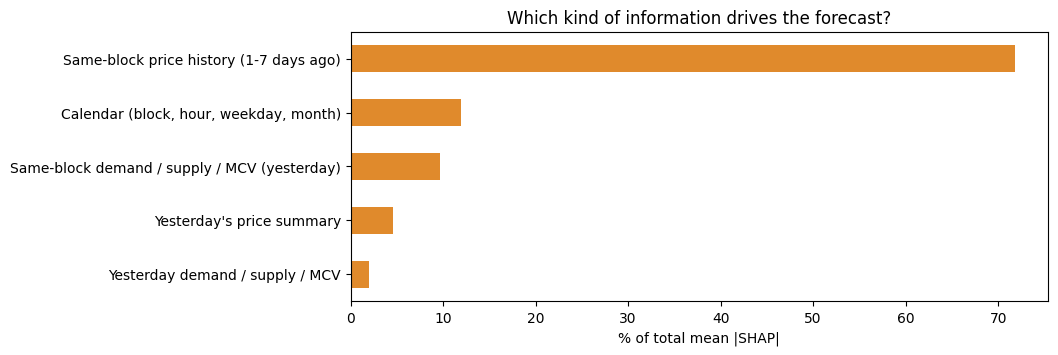

In [143]:
# ===== PART 16 | CELL 16.3: feature FAMILIES (easier to explain in the report) =====
def family(c):
    if c.startswith('mcp_lag') or c.startswith('sameblock'): return 'Same-block price history (1-7 days ago)'
    if c.startswith('y_') and any(k in c for k in ['demand', 'supply', 'mcv']): return 'Yesterday demand / supply / MCV'
    if c.startswith('y_'): return "Yesterday's price summary"
    if any(k in c for k in ['demand', 'supply', 'mcv', 'bid_ratio']): return 'Same-block demand / supply / MCV (yesterday)'
    return 'Calendar (block, hour, weekday, month)'
fam = imp.groupby(imp.index.map(family)).sum().sort_values(ascending=False)
print('\nShare of total |SHAP| by feature family:'); print((fam / fam.sum() * 100).round(1).to_string())
(fam / fam.sum() * 100).round(2).to_csv(f'{OUT}/metrics/shap_by_family.csv', header=['share_percent'])
ax = (fam / fam.sum() * 100).iloc[::-1].plot.barh(figsize=(9, 3.5), color='#e08a2c'); ax.set_xlabel('% of total mean |SHAP|'); ax.set_title('Which kind of information drives the forecast?')
plt.savefig(f'{OUT}/figures/phase3_shap_families.png', dpi=150, bbox_inches='tight'); plt.show()

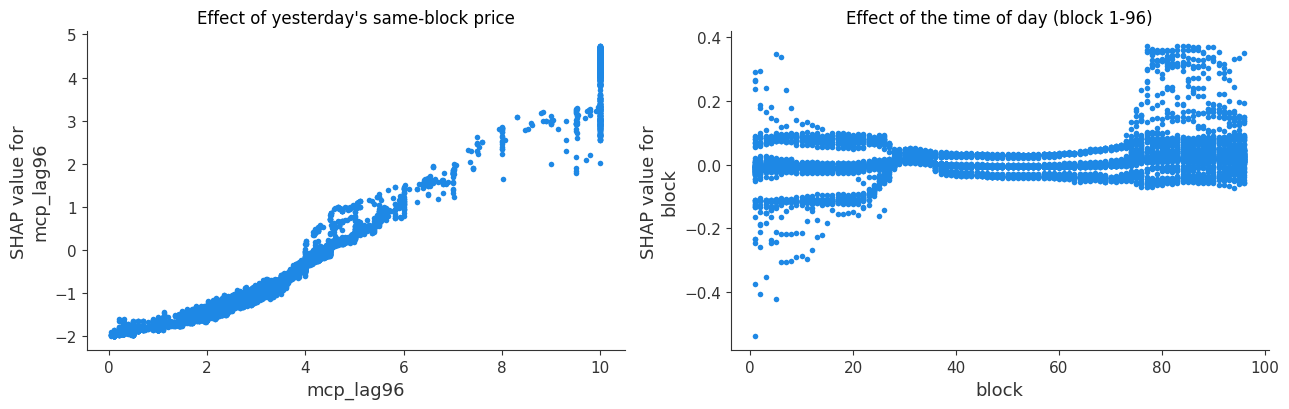

In [144]:
# ===== PART 16 | CELL 16.4: how does the model use yesterday's price and the time of day? =====
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
shap.dependence_plot('mcp_lag96', sv.values, Xte, interaction_index=None, ax=axes[0], show=False); axes[0].set_title('Effect of yesterday\'s same-block price')
shap.dependence_plot('block', sv.values, Xte, interaction_index=None, ax=axes[1], show=False); axes[1].set_title('Effect of the time of day (block 1-96)')
fig.tight_layout(); plt.savefig(f'{OUT}/figures/phase3_shap_dependence.png', dpi=150, bbox_inches='tight'); plt.show()

Evening ceiling block 2025-09-10 19:00:00: actual 10.00 | forecast 10.07 Rs/kWh


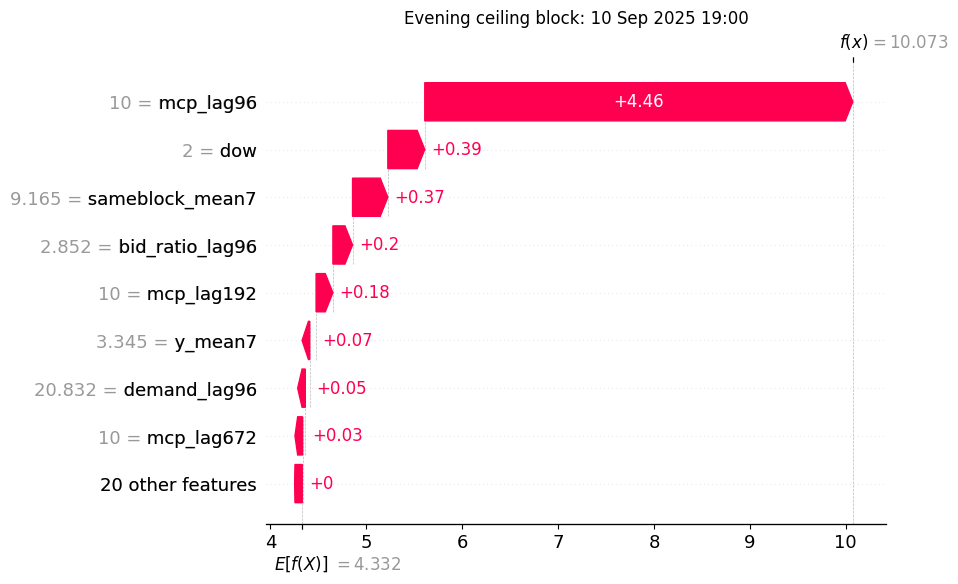

Cheap midday block 2025-08-20 12:00:00: actual 1.41 | forecast 1.85 Rs/kWh


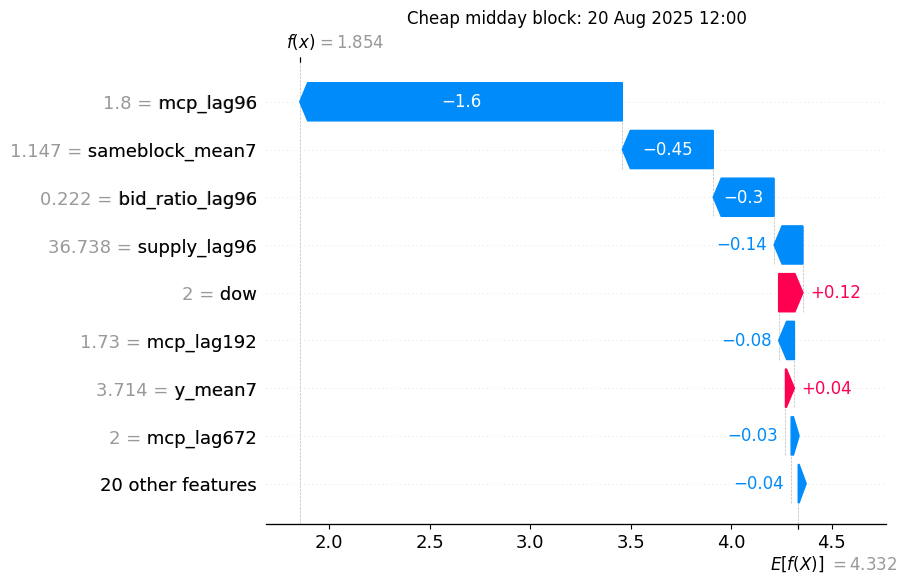

In [145]:
# ===== PART 16 | CELL 16.5: explaining two single forecasts (a ceiling block and a cheap midday block) =====
cases = {'Evening ceiling block': pd.Timestamp('2025-09-10 19:00'), 'Cheap midday block': pd.Timestamp('2025-08-20 12:00')}
for title, ts in cases.items():
    k = Xte.index.get_loc(ts)
    print(f'{title} {ts}: actual {mcp.loc[ts]:.2f} | forecast {float(m_trv.predict(Xte.iloc[[k]])[0]):.2f} Rs/kWh')
    plt.figure(); shap.plots.waterfall(sv[k], max_display=9, show=False)
    plt.title(f'{title}: {ts:%d %b %Y %H:%M}'); plt.savefig(f'{OUT}/figures/phase3_shap_waterfall_{title.split()[1].lower()}.png', dpi=150, bbox_inches='tight'); plt.show()

In [146]:
# ===== PART 17 | CELL 17.1: reusable feature builder + day-ahead forecast function (the web API will call this later) =====
def make_features(d):
    """d: DataFrame[mcp, demand, supply, mcv] on a regular 15-min index. Same logic as Part 9; the target day's rows may be NaN."""
    idx = d.index; g = pd.DataFrame(index=idx); g['mcp'] = d['mcp']
    for k in (96, 192, 288, 672): g[f'mcp_lag{k}'] = d['mcp'].shift(k)
    sb = pd.concat([d['mcp'].shift(96 * i) for i in range(1, 8)], axis=1)
    g['sameblock_mean7'], g['sameblock_std7'], g['sameblock_max7'] = sb.mean(axis=1), sb.std(axis=1), sb.max(axis=1)
    day = d['mcp'].groupby(idx.normalize()); prev = idx.normalize() - pd.Timedelta(days=1)
    daily = pd.DataFrame({'mean': day.mean(), 'std': day.std(), 'max': day.max(), 'min': day.min(), 'last': day.last(),
                          'cap_share': day.apply(lambda s: (s >= CEIL - 1e-9).mean())})
    for c in daily.columns: g[f'y_{c}'] = daily[c].reindex(prev).values
    g['y_mean7'] = daily['mean'].rolling(7).mean().reindex(prev).values
    for c in ['demand', 'supply', 'mcv']:
        g[f'{c}_lag96'] = d[c].shift(96); g[f'y_{c}_mean'] = d[c].groupby(idx.normalize()).mean().reindex(prev).values
    g['bid_ratio_lag96'] = g['demand_lag96'] / g['supply_lag96']
    blk = idx.hour * 4 + idx.minute // 15 + 1
    g['block'], g['hour'], g['dow'], g['month'] = blk, idx.hour, idx.dayofweek, idx.month
    g['is_weekend'] = (idx.dayofweek >= 5).astype(int); g['block_sin'], g['block_cos'] = np.sin(2 * np.pi * blk / 96), np.cos(2 * np.pi * blk / 96)
    return g

def forecast_day(hist, day, model, history_days=21):
    """Forecast the 96 blocks of `day` using ONLY data before that day."""
    day = pd.Timestamp(day).normalize()
    hist = hist.loc[day - pd.Timedelta(days=history_days): day - pd.Timedelta(minutes=15)]
    fut = pd.date_range(day, periods=96, freq='15min')
    ext = pd.concat([hist, pd.DataFrame(np.nan, index=fut, columns=hist.columns)])
    X = make_features(ext).loc[fut, FEATURES]
    return pd.Series(np.clip(model.predict(X), 0.0, CEIL), index=fut, name='forecast')

# --- verification: does the function reproduce the evaluated forecasts, and does it really ignore the target day's data? ---
ref = xgb_pred.reindex(dam.index)
for d in ['2025-07-15', '2025-08-20', '2025-09-10']:
    fc = forecast_day(dam, d, m_trv)
    X_chk = make_features(pd.concat([dam.loc[pd.Timestamp(d) - pd.Timedelta(days=21): pd.Timestamp(d) - pd.Timedelta(minutes=15)], pd.DataFrame(np.nan, index=fc.index, columns=dam.columns)])).loc[fc.index, FEATURES]
    fdiff = np.nanmax(np.abs(X_chk.values - f.loc[fc.index, FEATURES].values))
    poisoned = dam.copy(); poisoned.loc[d] = 999.0                                    # corrupt the target day itself
    unchanged = np.allclose(fc.values, forecast_day(poisoned, d, m_trv).values)
    print(f'{d}: max feature difference vs stored table {fdiff:.6f} | max forecast difference vs evaluated model {np.abs(fc - ref.loc[fc.index]).max():.4f} | unchanged when target day is corrupted: {unchanged}')

2025-07-15: max feature difference vs stored table 0.000000 | max forecast difference vs evaluated model 0.0000 | unchanged when target day is corrupted: True
2025-08-20: max feature difference vs stored table 0.000000 | max forecast difference vs evaluated model 0.0000 | unchanged when target day is corrupted: True
2025-09-10: max feature difference vs stored table 0.000000 | max forecast difference vs evaluated model 0.0000 | unchanged when target day is corrupted: True


Scenario A: 6 shiftable hours per day, any hour allowed, 93 test days
                                       avg price paid (Rs/kWh)  saving vs random (%)  share of max saving captured (%)  hit rate (cheapest hours found, %)  Rs saved, 1 MW x 6 h/day (lakh)
strategy                                                                                                                                                                                   
Random hours (no forecast)                                3.92                  0.00                              0.00                                 NaN                             0.00
Fixed rule: 6 h from 10:00 (no model)                     1.69                 57.04                             97.48                                 NaN                            12.49
XGBoost (tuned)                                           1.64                 58.11                             99.32                               93.01                        

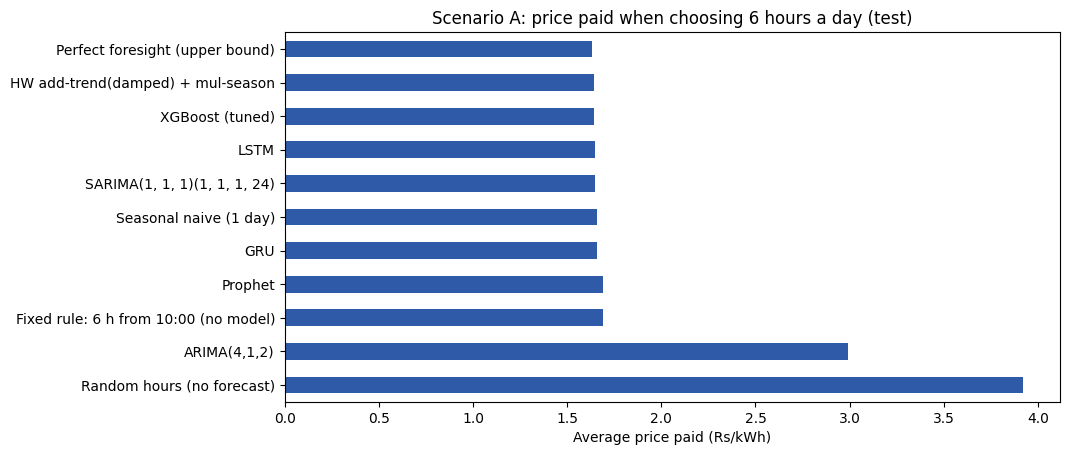

In [147]:
# ===== PART 17 | CELL 17.2: buyer savings simulation, scenario A (a buyer can shift N hours of load to ANY hours of the day) =====
yh = hourly(test['mcp']); n_days = len(yh) // 24
actual = yh.values.reshape(n_days, 24)                                   # actual hourly prices, one row per test day
def hourly_fc(name): return hourly(CLIPPED[name].reindex(test.index)).values.reshape(n_days, 24)
STRATS = ['XGBoost (tuned)', 'GRU', 'LSTM', 'Seasonal naive (1 day)', SARIMA_NAME, best_hw, 'Prophet', 'ARIMA' + best]

def simulate(N, hours=tuple(range(24)), fixed_start=10):
    hrs = list(hours); A = actual[:, hrs]
    res = {'Random hours (no forecast)': (A.mean(axis=1), None)}         # expected price of N randomly chosen allowed hours = their average
    cheapest = np.argsort(A, axis=1, kind='stable')[:, :N]
    pos = hrs.index(fixed_start)
    res[f'Fixed rule: {N} h from {fixed_start:02d}:00 (no model)'] = (A[:, pos:pos + N].mean(axis=1), None)
    for nm in STRATS:
        pick = np.argsort(hourly_fc(nm)[:, hrs], axis=1, kind='stable')[:, :N]       # the N hours the model thinks are cheapest
        hit = np.mean([len(set(pick[i]) & set(cheapest[i])) / N for i in range(n_days)])
        res[nm] = (np.take_along_axis(A, pick, axis=1).mean(axis=1), hit)
    res['Perfect foresight (upper bound)'] = (np.take_along_axis(A, cheapest, axis=1).mean(axis=1), 1.0)
    return res

def sim_table(N, **kw):
    res = simulate(N, **kw); rc = res['Random hours (no forecast)'][0].mean(); oc = res['Perfect foresight (upper bound)'][0].mean(); rows = []
    for nm, (c, hit) in res.items():
        rows.append({'strategy': nm, 'avg price paid (Rs/kWh)': c.mean(), 'saving vs random (%)': (rc - c.mean()) / rc * 100,
                     'share of max saving captured (%)': (rc - c.mean()) / (rc - oc) * 100,
                     'hit rate (cheapest hours found, %)': np.nan if hit is None else hit * 100,
                     f'Rs saved, 1 MW x {N} h/day (lakh)': (rc - c.mean()) * 1000 * N * n_days / 1e5})
    return pd.DataFrame(rows).set_index('strategy').round(2)

simA = sim_table(6)
print(f'Scenario A: 6 shiftable hours per day, any hour allowed, {n_days} test days'); print(simA.to_string())
simA.to_csv(f'{OUT}/metrics/buyer_savings_scenarioA.csv')
ax = simA['avg price paid (Rs/kWh)'].sort_values(ascending=False).plot.barh(figsize=(10, 4.8), color='#2f5aa8')
ax.set_xlabel('Average price paid (Rs/kWh)'); ax.set_ylabel(''); ax.set_title('Scenario A: price paid when choosing 6 hours a day (test)')
plt.savefig(f'{OUT}/figures/phase3_buyer_savings_A.png', dpi=150, bbox_inches='tight'); plt.show()

In [148]:
# ===== PART 17 | CELL 17.3: how does the result change with the amount of shiftable load? =====
rows = []
for n in (3, 6, 9, 12):
    r = simulate(n); rc = r['Random hours (no forecast)'][0].mean(); oc = r['Perfect foresight (upper bound)'][0].mean()
    for nm in ['XGBoost (tuned)', 'GRU', 'Seasonal naive (1 day)', f'Fixed rule: {n} h from 10:00 (no model)']:
        rows.append({'hours shifted': n, 'strategy': nm.replace(f'{n} h ', ''), 'price paid': r[nm][0].mean(), 'saving vs random %': (rc - r[nm][0].mean()) / rc * 100,
                     'max saving captured %': (rc - r[nm][0].mean()) / (rc - oc) * 100})
sens = pd.DataFrame(rows); print(sens.round(2).to_string(index=False)); sens.round(3).to_csv(f'{OUT}/metrics/buyer_savings_sensitivity.csv', index=False)

 hours shifted                          strategy  price paid  saving vs random %  max saving captured %
             3                   XGBoost (tuned)        1.53               61.01                  97.98
             3                               GRU        1.57               60.01                  96.38
             3            Seasonal naive (1 day)        1.55               60.58                  97.28
             3 Fixed rule: from 10:00 (no model)        1.58               59.79                  96.02
             6                   XGBoost (tuned)        1.64               58.11                  99.32
             6                               GRU        1.66               57.81                  98.81
             6            Seasonal naive (1 day)        1.66               57.76                  98.72
             6 Fixed rule: from 10:00 (no model)        1.69               57.04                  97.48
             9                   XGBoost (tuned)        1.88    

Scenario B: 2 shiftable hours per day, allowed only between 17:00 and 23:00
                                       avg price paid (Rs/kWh)  saving vs random (%)  share of max saving captured (%)  hit rate (cheapest hours found, %)  Rs saved, 1 MW x 2 h/day (lakh)
strategy                                                                                                                                                                                   
Random hours (no forecast)                                6.87                  0.00                              0.00                                 NaN                             0.00
Fixed rule: 2 h from 17:00 (no model)                     4.13                 39.96                             93.19                                 NaN                             5.11
XGBoost (tuned)                                           3.95                 42.59                             99.31                               95.70                  

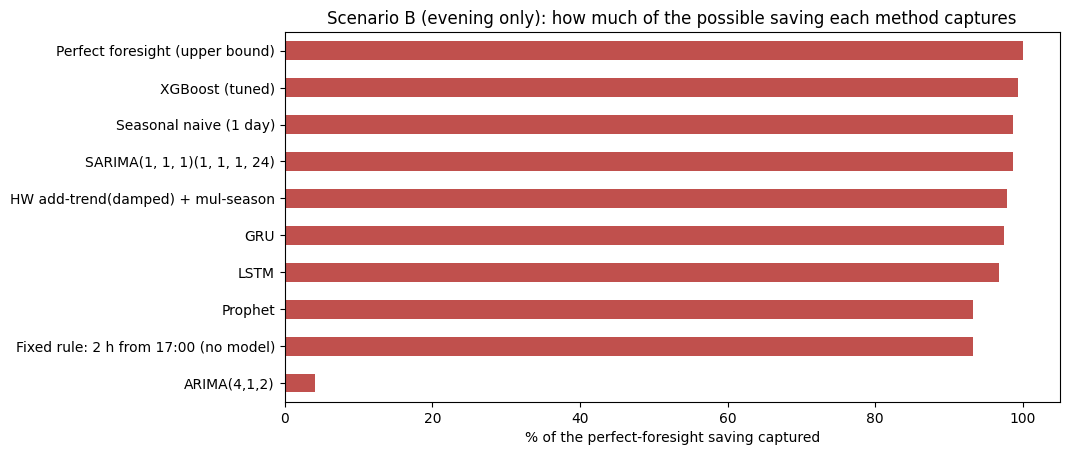

In [149]:
# ===== PART 17 | CELL 17.4: scenario B - evening-only flexibility (the hard case): shift 2 hours within 17:00-23:00 =====
EVE = tuple(range(17, 24))
simB = sim_table(2, hours=EVE, fixed_start=17)
print('Scenario B: 2 shiftable hours per day, allowed only between 17:00 and 23:00'); print(simB.to_string())
simB.to_csv(f'{OUT}/metrics/buyer_savings_scenarioB.csv')
ax = simB['share of max saving captured (%)'].drop(['Random hours (no forecast)']).sort_values().plot.barh(figsize=(10, 4.8), color='#c0504d')
ax.set_xlabel('% of the perfect-foresight saving captured'); ax.set_ylabel(''); ax.set_title('Scenario B (evening only): how much of the possible saving each method captures')
plt.savefig(f'{OUT}/figures/phase3_buyer_savings_B.png', dpi=150, bbox_inches='tight'); plt.show()

Most often among the 6 cheapest hours (actual): 13:00 (100%), 12:00 (99%), 10:00 (98%), 11:00 (97%), 14:00 (89%), 09:00 (82%)


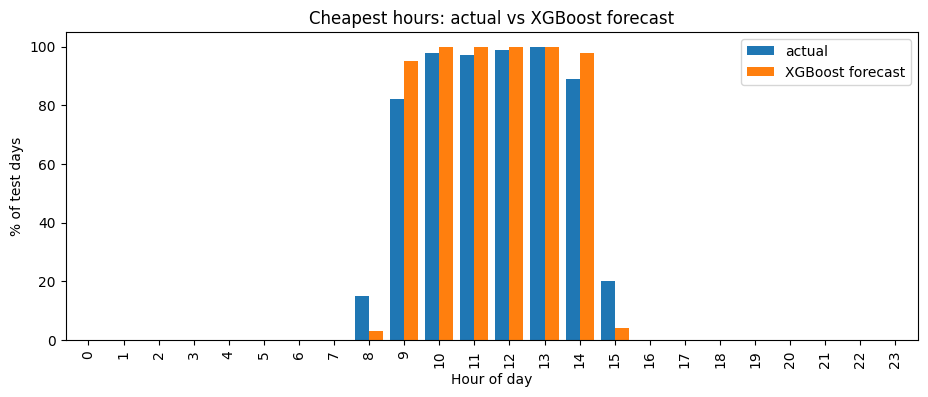

In [150]:
# ===== PART 17 | CELL 17.5: which hours are the cheap ones? (share of test days each hour is among the 6 cheapest) =====
cheap_act = np.zeros(24); cheap_fc = np.zeros(24); fcx = hourly_fc('XGBoost (tuned)')
for i in range(n_days):
    cheap_act[np.argsort(actual[i], kind='stable')[:6]] += 1; cheap_fc[np.argsort(fcx[i], kind='stable')[:6]] += 1
share = pd.DataFrame({'actual': cheap_act / n_days * 100, 'XGBoost forecast': cheap_fc / n_days * 100}, index=range(24)).round(0)
print('Most often among the 6 cheapest hours (actual):', ', '.join(f'{h:02d}:00 ({share.loc[h, "actual"]:.0f}%)' for h in share['actual'].sort_values(ascending=False).index[:6]))
ax = share.plot.bar(figsize=(11, 4), width=0.8); ax.set_xlabel('Hour of day'); ax.set_ylabel('% of test days'); ax.set_title('Cheapest hours: actual vs XGBoost forecast')
plt.savefig(f'{OUT}/figures/phase3_cheapest_hours.png', dpi=150, bbox_inches='tight'); plt.show()

In [151]:
# ===== PART 17 | CELL 17.6: deployment model (trained on ALL data), next-day forecast, and the model card =====
import json, xgboost, sklearn
all_rows = f['mcp_lag672'].notna()
m_deploy = xgb.XGBRegressor(n_estimators=int(n_best * 1.15), **common).fit(f.loc[all_rows, FEATURES], f.loc[all_rows, 'mcp'])
m_deploy.save_model(f'{OUT}/data/xgboost_deploy.json')

next_day = dam.index.max().normalize() + pd.Timedelta(days=1)
nf = forecast_day(dam, next_day, m_deploy)                                # a real out-of-sample forecast: the actual prices are not in the data
nf.to_csv(f'{OUT}/forecasts/next_day_forecast.csv', header=['forecast_mcp'], index_label='timestamp')
nh = hourly(nf); nhh = nh.groupby(nh.index.hour).mean()
print(f'Next-day forecast for {next_day.date()} (made with data up to {dam.index.max()}):')
print('  6 cheapest hours :', ', '.join(f'{h:02d}:00 (Rs {v:.2f})' for h, v in nhh.nsmallest(6).items()))
print('  hours at/near the ceiling (forecast >= 9.5):', [f'{h:02d}:00' for h, v in nhh.items() if v >= 9.5])

t15 = results_table('test', '15-min').loc['XGBoost (tuned)']; th = results_table('test', 'hourly').loc['XGBoost (tuned)']
card = {'name': 'GridCast India - day-ahead DAM price forecaster', 'version': '1.0', 'created': str(pd.Timestamp.now().date()),
        'model': 'XGBoost regressor (tuned)', 'target': 'IEX Day-Ahead Market MCP, Rs/kWh, 96 blocks per day',
        'forecast_protocol': 'Day-ahead: uses only information up to the previous day 23:45; output clipped to [0, ceiling]; ceiling = 10 Rs/kWh',
        'features': FEATURES, 'hyperparameters': {k: (v.item() if hasattr(v, 'item') else v) for k, v in common.items()}, 'n_trees': int(n_best * 1.15),
        'evaluation_model': {'trained_on': f'{f.index[all_rows].min()} to {VAL_END}', 'test_period': f'{TEST_START} to {dam.index.max()}',
                             'test_hourly': {k: round(float(v), 4) for k, v in th.items()}, 'test_15min': {k: round(float(v), 4) for k, v in t15.items()}},
        'deployment_model': {'file': 'xgboost_deploy.json', 'trained_on': f'{f.index[all_rows].min()} to {dam.index.max()}', 'note': 'same hyperparameters, refit on all available data'},
        'libraries': {'xgboost': xgboost.__version__, 'pandas': pd.__version__, 'numpy': np.__version__, 'scikit-learn': sklearn.__version__},
        'known_limitations': ['One exchange (IEX DAM) and one 93-day test period', "Depends heavily on yesterday's same-block price (about 72% of SHAP importance)",
                              'Weaker when the price level shifts from the day before (see Part 15)', 'Data ends 2025-10-01; no weather or fuel-price inputs']}
json.dump(card, open(f'{OUT}/data/model_card.json', 'w'), indent=2, default=str)
print('\nSaved: xgboost_deploy.json, next_day_forecast.csv, model_card.json')
print(json.dumps(card['evaluation_model'], indent=2, default=str)[:600])

Next-day forecast for 2025-10-02 (made with data up to 2025-10-01 23:45:00):
  6 cheapest hours : 13:00 (Rs 1.28), 12:00 (Rs 1.47), 11:00 (Rs 1.52), 10:00 (Rs 1.59), 09:00 (Rs 1.65), 14:00 (Rs 1.84)
  hours at/near the ceiling (forecast >= 9.5): ['19:00']

Saved: xgboost_deploy.json, next_day_forecast.csv, model_card.json
{
  "trained_on": "2023-01-08 00:00:00 to 2025-06-30 23:45",
  "test_period": "2025-07-01 00:00 to 2025-10-01 23:45:00",
  "test_hourly": {
    "MAE": 0.502,
    "RMSE": 0.877,
    "MAPE_%": 27.586,
    "sMAPE_%": 17.031,
    "MASE": 0.732
  },
  "test_15min": {
    "MAE": 0.518,
    "RMSE": 0.954,
    "MAPE_%": 30.111,
    "sMAPE_%": 17.516,
    "MASE": 0.742
  }
}


In [152]:
# ===== PART 18 | CELL 18.1: Diebold-Mariano test (HAC variance, small-sample correction) on daily test errors =====
from scipy import stats
yh = hourly(test['mcp'])
def daily_loss(pr, kind):
    e = yh - hourly(pr.reindex(test.index))
    l = e.abs() if kind == 'abs' else e ** 2
    return l.groupby(l.index.normalize()).mean()                             # one loss value per test day

def dm_test(loss_a, loss_b, h=1):
    """Gain of A over B = loss_B - loss_A (positive = A is better). Newey-West variance + Harvey-Leybourne-Newbold correction."""
    d = (loss_b - loss_a).dropna().values; T = len(d)
    K = int(np.floor(4 * (T / 100) ** (2 / 9)))                              # Bartlett bandwidth
    dc = d - d.mean(); lrv = np.dot(dc, dc) / T
    for k in range(1, K + 1):
        lrv += 2 * (1 - k / (K + 1)) * np.dot(dc[k:], dc[:-k]) / T
    se = np.sqrt(lrv / T)
    dm = d.mean() / se * np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    p = 2 * (1 - stats.t.cdf(abs(dm), df=T - 1)); tcrit = stats.t.ppf(0.975, T - 1)
    return d.mean(), d.mean() - tcrit * se, d.mean() + tcrit * se, dm, p

pairs = [('XGBoost (tuned)', 'Seasonal naive (1 day)'), ('XGBoost (tuned)', 'GRU'), ('XGBoost (tuned)', SARIMA_NAME),
         ('GRU', 'Seasonal naive (1 day)'), ('LSTM', 'Seasonal naive (1 day)'), (SARIMA_NAME, 'Seasonal naive (1 day)'), ('GRU', 'LSTM')]
rows = []
for kind, lab in [('abs', 'absolute error'), ('sq', 'squared error')]:
    for a, b in pairs:
        g, lo, hi, dm, p = dm_test(daily_loss(CLIPPED[a], kind), daily_loss(CLIPPED[b], kind))
        rows.append({'loss': lab, 'A better than B?': f'{a}  vs  {b}', 'mean daily gain of A': g, '95% CI low': lo, '95% CI high': hi, 'DM stat': dm, 'p-value': p,
                     'significant (5%)': 'yes' if p < 0.05 else 'no', f'after Bonferroni ({len(pairs)} tests)': 'yes' if p < 0.05 / len(pairs) else 'no'})
dm_tab = pd.DataFrame(rows)
pd.set_option('display.width', 250); pd.set_option('display.max_colwidth', 60)
print('Diebold-Mariano tests over', len(daily_loss(CLIPPED['GRU'], 'abs')), 'test days (gain > 0 means the FIRST model is better)')
print(dm_tab.round(4).to_string(index=False))
dm_tab.round(5).to_csv(f'{OUT}/metrics/diebold_mariano_tests.csv', index=False)

Diebold-Mariano tests over 93 test days (gain > 0 means the FIRST model is better)
          loss                                         A better than B?  mean daily gain of A  95% CI low  95% CI high  DM stat  p-value significant (5%) after Bonferroni (7 tests)
absolute error              XGBoost (tuned)  vs  Seasonal naive (1 day)                0.2626      0.1791       0.3460   6.2163   0.0000              yes                        yes
absolute error                                 XGBoost (tuned)  vs  GRU                0.3281      0.2666       0.3895  10.5508   0.0000              yes                        yes
absolute error        XGBoost (tuned)  vs  SARIMA(1, 1, 1)(1, 1, 1, 24)                0.4613      0.3674       0.5552   9.7015   0.0000              yes                        yes
absolute error                          GRU  vs  Seasonal naive (1 day)               -0.0655     -0.1474       0.0164  -1.5793   0.1177               no                         no
absolute err

In [153]:
# ===== PART 18 | CELL 18.2: prediction intervals - XGBoost quantile regression (10% / 50% / 90%) + conformal calibration =====
import xgboost as xgb
QS = [0.1, 0.5, 0.9]
q_tr  = (f.index <= TRAIN_END) & f['mcp_lag672'].notna(); q_va = (f.index >= VAL_START) & (f.index <= VAL_END)
q_trv = (f.index <= VAL_END) & f['mcp_lag672'].notna();  q_te = f.index >= TEST_START
qp = {**common, 'objective': 'reg:quantileerror', 'quantile_alpha': np.array(QS)}      # same tuned settings, quantile loss instead
def fit_q(rows): return xgb.XGBRegressor(n_estimators=n_best, **qp).fit(f.loc[rows, FEATURES], f.loc[rows, 'mcp'])
def pred_q(m, rows): return np.clip(np.sort(m.predict(f.loc[rows, FEATURES]), axis=1), 0.0, CEIL)     # sorted so the quantiles never cross

qv = pred_q(fit_q(q_tr), q_va);  yv = f.loc[q_va, 'mcp'].values            # validation intervals from the train-only model
qt = pred_q(fit_q(q_trv), q_te); yt = f.loc[q_te, 'mcp'].values            # test intervals from the train+validation model

# conformal calibration on the validation period (conformalised quantile regression): widen both sides by Q
alpha = 0.2; n = len(yv)
scores = np.maximum(qv[:, 0] - yv, yv - qv[:, 2])
Q = float(np.quantile(scores, min(1.0, np.ceil((n + 1) * (1 - alpha)) / n)))
lo_c, hi_c = np.clip(qt[:, 0] - Q, 0, CEIL), np.clip(qt[:, 2] + Q, 0, CEIL)
print(f'Conformal widening on each side: {Q:.3f} Rs/kWh (validation, nominal coverage 80%)')

def cov(lo, hi, y, mask=None):
    m = np.ones(len(y), bool) if mask is None else mask
    return float(np.mean((y[m] >= lo[m] - 1e-9) & (y[m] <= hi[m] + 1e-9)) * 100)
capm = (yt >= CEIL - 1e-6)
rows = [{'interval': 'Raw quantile 10%-90%', 'coverage % (target 80)': cov(qt[:, 0], qt[:, 2], yt), 'coverage on validation %': cov(qv[:, 0], qv[:, 2], yv),
         'coverage at ceiling blocks %': cov(qt[:, 0], qt[:, 2], yt, capm), 'coverage elsewhere %': cov(qt[:, 0], qt[:, 2], yt, ~capm), 'mean width (Rs/kWh)': float(np.mean(qt[:, 2] - qt[:, 0]))},
        {'interval': 'Conformal-calibrated', 'coverage % (target 80)': cov(lo_c, hi_c, yt), 'coverage on validation %': np.nan,
         'coverage at ceiling blocks %': cov(lo_c, hi_c, yt, capm), 'coverage elsewhere %': cov(lo_c, hi_c, yt, ~capm), 'mean width (Rs/kWh)': float(np.mean(hi_c - lo_c))}]
interval_tab = pd.DataFrame(rows).set_index('interval').round(1); print(interval_tab.to_string())
pin = lambda y, q, a: float(np.mean(np.maximum(a * (y - q), (a - 1) * (y - q))))
print(f'\nMedian forecast: MAE {np.mean(np.abs(yt - qt[:, 1])):.3f} (15-min, test) | pinball loss q10 {pin(yt, qt[:, 0], 0.1):.3f}, q50 {pin(yt, qt[:, 1], 0.5):.3f}, q90 {pin(yt, qt[:, 2], 0.9):.3f}')
interval_tab.to_csv(f'{OUT}/metrics/prediction_intervals.csv')
pd.DataFrame({'q10': qt[:, 0], 'q50': qt[:, 1], 'q90': qt[:, 2], 'conf_lo': lo_c, 'conf_hi': hi_c, 'actual': yt}, index=f.index[q_te]).to_csv(f'{OUT}/forecasts/xgboost_intervals_test.csv')

Conformal widening on each side: 0.005 Rs/kWh (validation, nominal coverage 80%)
                      coverage % (target 80)  coverage on validation %  coverage at ceiling blocks %  coverage elsewhere %  mean width (Rs/kWh)
interval                                                                                                                                       
Raw quantile 10%-90%                    84.8                      79.7                          89.0                  84.1                  2.8
Conformal-calibrated                    84.9                       NaN                          89.2                  84.3                  2.8

Median forecast: MAE 0.584 (15-min, test) | pinball loss q10 0.159, q50 0.292, q90 0.197


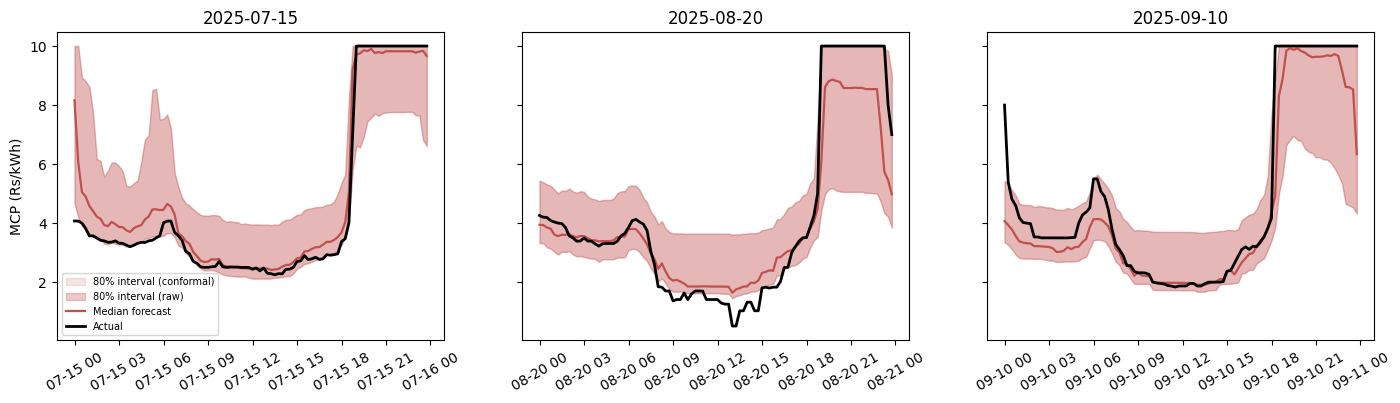

In [154]:
# ===== PART 18 | CELL 18.3: look at the bands on three test days =====
bands = pd.DataFrame({'q10': qt[:, 0], 'q50': qt[:, 1], 'q90': qt[:, 2], 'lo': lo_c, 'hi': hi_c}, index=f.index[q_te])
fig, axes = plt.subplots(1, 3, figsize=(17, 4), sharey=True)
for ax, dday in zip(axes, ['2025-07-15', '2025-08-20', '2025-09-10']):
    b = bands.loc[dday]; ax.fill_between(b.index, b['lo'], b['hi'], color='#c0504d', alpha=.15, label='80% interval (conformal)')
    ax.fill_between(b.index, b['q10'], b['q90'], color='#c0504d', alpha=.30, label='80% interval (raw)')
    ax.plot(b['q50'], color='#c0504d', lw=1.6, label='Median forecast'); ax.plot(dam['mcp'].loc[dday], 'k', lw=2, label='Actual')
    ax.set_title(dday); ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=7)
plt.savefig(f'{OUT}/figures/phase3_prediction_intervals.png', dpi=150, bbox_inches='tight'); plt.show()

  done Jan 2024-Mar 2024  (3s)
  done Apr 2024-Jun 2024  (6s)
  done Jul 2024-Sep 2024  (9s)
  done Oct 2024-Dec 2024  (13s)
  done Jan 2025-Mar 2025  (17s)
  done Apr 2025-Jun 2025  (21s)
  done Jul 2025-Oct 2025  (26s)

Hourly MAE (Rs/kWh) in each out-of-sample quarter, model refitted on all data before the quarter:
                   train days  test days  XGBoost (default) MAE  XGBoost (tuned settings) MAE  Seasonal naive (1 day) MAE  Seasonal naive (1 week) MAE  gain vs seasonal naive, MAE % (default)  gain vs seasonal naive, MAE % (tuned)
window                                                                                                                                                                                                                                
Jan 2024-Mar 2024         358         91                  0.479                         0.452                       0.546                        0.766                                   12.240                           

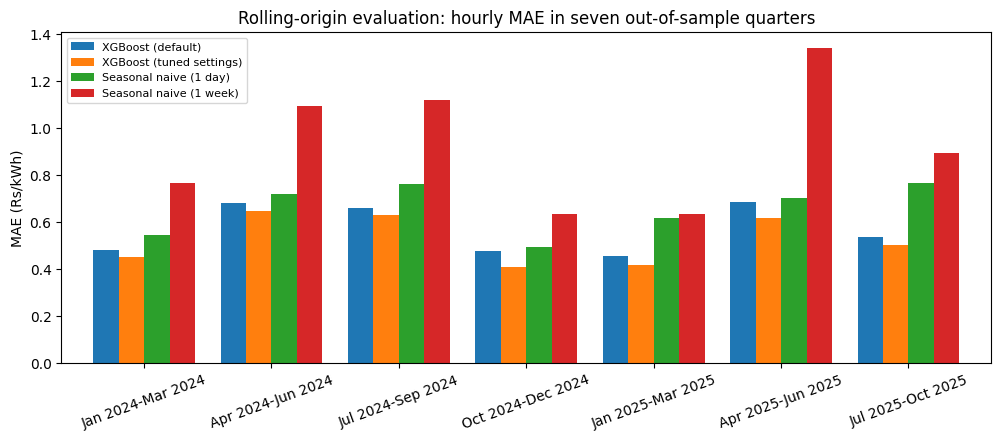

In [155]:
# ===== PART 18 | CELL 18.4: rolling-origin evaluation - seven out-of-sample quarters instead of one =====
DEFAULT_P = dict(n_estimators=400, learning_rate=0.05, max_depth=6, subsample=0.8, colsample_bytree=0.8, tree_method='hist', n_jobs=-1, random_state=42)
TUNED_P = {**common, 'n_estimators': int(n_best * 1.15)}
starts = pd.to_datetime(['2024-01-01', '2024-04-01', '2024-07-01', '2024-10-01', '2025-01-01', '2025-04-01', '2025-07-01'])
ends = list(starts[1:] - pd.Timedelta(minutes=15)) + [dam.index.max()]
rows = []; t0 = time.time()
for s, e in zip(starts, ends):
    trn = (f.index < s) & f['mcp_lag672'].notna(); win = (f.index >= s) & (f.index <= e)
    yh_w = hourly(dam['mcp'].loc[s:e]); out = {'window': f'{s:%b %Y}-{e:%b %Y}', 'train days': int(trn.sum() // 96), 'test days': len(yh_w) // 24}
    def mae_rmse(pr15):
        d = yh_w - hourly(pr15.reindex(dam['mcp'].loc[s:e].index)); return d.abs().mean(), np.sqrt((d ** 2).mean())
    for nm, params in [('XGBoost (default)', DEFAULT_P), ('XGBoost (tuned settings)', TUNED_P)]:
        m = xgb.XGBRegressor(**params).fit(f.loc[trn, FEATURES], f.loc[trn, 'mcp'])
        pr = pd.Series(np.clip(m.predict(f.loc[win, FEATURES]), 0.0, CEIL), index=f.index[win])
        out[f'{nm} MAE'], out[f'{nm} RMSE'] = mae_rmse(pr)
    out['Seasonal naive (1 day) MAE'], out['Seasonal naive (1 day) RMSE'] = mae_rmse(pred_seas_day)
    out['Seasonal naive (1 week) MAE'], _ = mae_rmse(pred_seas_week)
    rows.append(out); print(f'  done {out["window"]}  ({time.time() - t0:.0f}s)')
ro = pd.DataFrame(rows).set_index('window')
ro['gain vs seasonal naive, MAE % (default)'] = (ro['Seasonal naive (1 day) MAE'] - ro['XGBoost (default) MAE']) / ro['Seasonal naive (1 day) MAE'] * 100
ro['gain vs seasonal naive, MAE % (tuned)'] = (ro['Seasonal naive (1 day) MAE'] - ro['XGBoost (tuned settings) MAE']) / ro['Seasonal naive (1 day) MAE'] * 100
show = ro[['train days', 'test days', 'XGBoost (default) MAE', 'XGBoost (tuned settings) MAE', 'Seasonal naive (1 day) MAE', 'Seasonal naive (1 week) MAE',
           'gain vs seasonal naive, MAE % (default)', 'gain vs seasonal naive, MAE % (tuned)']].round(3)
pd.set_option('display.width', 250); print('\nHourly MAE (Rs/kWh) in each out-of-sample quarter, model refitted on all data before the quarter:'); print(show.to_string())
print(f'\nXGBoost (default) beats seasonal naive (1 day) in {(ro["XGBoost (default) MAE"] < ro["Seasonal naive (1 day) MAE"]).sum()} of {len(ro)} quarters (MAE) and in {(ro["XGBoost (default) RMSE"] < ro["Seasonal naive (1 day) RMSE"]).sum()} of {len(ro)} (RMSE)')
print(f'Average MAE gain: {ro["gain vs seasonal naive, MAE % (default)"].mean():.1f}% (default settings), {ro["gain vs seasonal naive, MAE % (tuned)"].mean():.1f}% (tuned settings)')
show.to_csv(f'{OUT}/metrics/rolling_origin_evaluation.csv')

ax = ro[['XGBoost (default) MAE', 'XGBoost (tuned settings) MAE', 'Seasonal naive (1 day) MAE', 'Seasonal naive (1 week) MAE']].rename(columns=lambda c: c.replace(' MAE', '')).plot.bar(figsize=(12, 4.3), width=0.8, rot=20)
ax.set_ylabel('MAE (Rs/kWh)'); ax.set_xlabel(''); ax.set_title('Rolling-origin evaluation: hourly MAE in seven out-of-sample quarters'); ax.legend(fontsize=8)
plt.savefig(f'{OUT}/figures/phase3_rolling_origin.png', dpi=150, bbox_inches='tight'); plt.show()

Part 19: improvement experiments (v2 features, delta target, LightGBM, ensemble

In [156]:
# ===== PART 19 | CELL 19.1: richer day-ahead features (v2) =====
# Every new feature uses only information up to yesterday 23:45 (shift >= 96), so there is no leakage.
def make_features_v2(d):
    g = make_features(d)                                   # the 28 features from Part 17
    idx, m = d.index, d['mcp']
    prev = idx.normalize() - pd.Timedelta(days=1)
    g['d_lag96_192']   = g['mcp_lag96'] - g['mcp_lag192']             # momentum: is yesterday higher than the day before?
    g['dev_lag96_sb7'] = g['mcp_lag96'] - g['sameblock_mean7']        # yesterday vs its own 7-day normal
    sb = pd.concat([m.shift(96 * i) for i in range(1, 8)], axis=1)
    g['sameblock_med7'], g['sameblock_min7'] = sb.median(axis=1), sb.min(axis=1)
    g['sameblock_mean3'] = sb.iloc[:, :3].mean(axis=1)                # short memory (last 3 days)
    capf = (m >= 9.99).astype(float).where(m.notna())                 # at the ceiling (10 now, 12 earlier)
    g['lag96_at_cap'] = capf.shift(96)
    g['cap_cnt7'] = pd.concat([capf.shift(96 * i) for i in range(1, 8)], axis=1).mean(axis=1)
    g['hr_mean_lag96'] = m.groupby([idx.normalize(), idx.hour]).transform('mean').shift(96)   # same hour yesterday (smooths 15-min noise)
    eve = m[idx.hour >= 17];                       g['y_eve'] = eve.groupby(eve.index.normalize()).mean().reindex(prev).values
    mid = m[(idx.hour >= 10) & (idx.hour <= 15)];  g['y_mid'] = mid.groupby(mid.index.normalize()).mean().reindex(prev).values
    dm = m.groupby(idx.normalize()).mean();        g['y_mean_chg'] = (dm - dm.shift(1)).reindex(prev).values
    ratio = d['demand'] / d['supply']
    g['bid_ratio_sb7'] = pd.concat([ratio.shift(96 * i) for i in range(1, 8)], axis=1).mean(axis=1)
    return g

f2 = make_features_v2(dam)
FEATURES2 = [c for c in f2.columns if c != 'mcp']
print('Features:', len(FEATURES), '->', len(FEATURES2))
print('Sanity (old features unchanged):', float(np.nanmax(np.abs(f2[FEATURES].values - f[FEATURES].values))))
f2.to_csv(f'{OUT}/data/dam_features_v2.csv', index_label='timestamp')

Features: 28 -> 40
Sanity (old features unchanged): 0.0


In [157]:
# ===== PART 19 | CELL 19.2: runner (same protocol as Part 10: tune on val, refit on train+val for test) =====
import lightgbm as lgb      # preinstalled on Kaggle

def make_model(kind, n, early=False):
    if kind == 'xgb':
        extra = dict(early_stopping_rounds=50, eval_metric='mae') if early else {}
        return xgb.XGBRegressor(n_estimators=n, **extra, **common)           # `common` = tuned params from Part 10.3
    return lgb.LGBMRegressor(n_estimators=n, learning_rate=0.03, num_leaves=31, min_child_samples=40, subsample=0.7,
                             subsample_freq=1, colsample_bytree=0.8, reg_lambda=10, objective='l1',
                             random_state=42, n_jobs=-1, verbose=-1)

def run(name, kind, feats, delta=False, halflife=None):
    """delta=True: model predicts (price - yesterday's same-block price) and we add it back.
       halflife=days: recent days get more weight (the price level drifted a lot: 12 -> 10 ceiling, mean 4.99 -> 3.92)."""
    tgt = f2['mcp'] - f2['mcp_lag96'] if delta else f2['mcp']
    def wts(mask):
        if halflife is None: return None
        t = f2.index[mask]; age = (t.max() - t).total_seconds() / 86400
        return 0.5 ** (np.asarray(age) / halflife)
    Xa, ya, Xv, yv_ = f2.loc[tr_m, feats], tgt[tr_m], f2.loc[va_m, feats], tgt[va_m]
    Xb, yb, Xt = f2.loc[trv_m, feats], tgt[trv_m], f2.loc[te_m, feats]
    if kind == 'xgb':
        m1 = make_model('xgb', 1500, early=True).fit(Xa, ya, sample_weight=wts(tr_m), eval_set=[(Xv, yv_)], verbose=False)
        n_it = int(m1.best_iteration) + 1
    else:
        m1 = make_model('lgb', 3000).fit(Xa, ya, sample_weight=wts(tr_m), eval_set=[(Xv, yv_)], eval_metric='l1',
                                         callbacks=[lgb.early_stopping(50, verbose=False)])
        n_it = int(m1.best_iteration_)
    m2 = make_model(kind, int(n_it * 1.15) + 1).fit(Xb, yb, sample_weight=wts(trv_m))
    bv = f2.loc[va_m, 'mcp_lag96'].values if delta else 0.0
    bt = f2.loc[te_m, 'mcp_lag96'].values if delta else 0.0
    pred = pd.concat([as_series(m1.predict(Xv) + bv, Xv.index), as_series(m2.predict(Xt) + bt, Xt.index)])
    evaluate(name, pred.reindex(dam.index))
    print(f'{name:28s} trees {n_it:4d}', '| test hourly MAE %.3f RMSE %.3f' % tuple(results_table('test', 'hourly').loc[name, ['MAE', 'RMSE']]))
    return pred, m2

In [158]:
# ===== PART 19 | CELL 19.3: experiments (each one changes ONE thing, so you can say what helped) =====
P = {}
P['XGB v2'],                _      = run('XGB v2',                'xgb', FEATURES2)                              # only new features
P['XGB v2 delta'],          _      = run('XGB v2 delta',          'xgb', FEATURES2, delta=True)                  # + delta target
P['XGB v2 delta recency'],  m_best = run('XGB v2 delta recency',  'xgb', FEATURES2, delta=True, halflife=180)    # + recency weights
P['LGBM v2 delta'],         _      = run('LightGBM v2 delta',     'lgb', FEATURES2, delta=True)
P['LGBM v2 delta recency'], _      = run('LightGBM v2 delta recency', 'lgb', FEATURES2, delta=True, halflife=180)
print('\nTEST - hourly (top 8)'); print(results_table('test', 'hourly').head(8).to_string())
print('\nVALIDATION - hourly (top 8)  <- choose models using THIS table, not test'); print(results_table('val', 'hourly').head(8).to_string())

XGB v2                       trees  398 | test hourly MAE 0.517 RMSE 0.887
XGB v2 delta                 trees  175 | test hourly MAE 0.541 RMSE 0.966
XGB v2 delta recency         trees  215 | test hourly MAE 0.532 RMSE 0.943
LightGBM v2 delta            trees  176 | test hourly MAE 0.548 RMSE 0.980
LightGBM v2 delta recency    trees  130 | test hourly MAE 0.554 RMSE 0.981

TEST - hourly (top 8)
                             MAE   RMSE  MAPE_%  sMAPE_%   MASE
model                                                          
XGBoost (walk-forward)     0.497  0.876  27.601   16.920  0.724
XGBoost (tuned)            0.502  0.877  27.586   17.031  0.732
XGB v2                     0.517  0.887  27.857   17.857  0.753
XGB v2 delta recency       0.532  0.943  28.359   18.253  0.775
XGBoost (default)          0.536  0.865  26.883   17.826  0.781
XGB v2 delta               0.541  0.966  28.574   18.020  0.789
LightGBM v2 delta          0.548  0.980  28.794   18.374  0.799
LightGBM v2 delta recency 

In [159]:
# ===== PART 19 | CELL 19.4: ensemble (simple average of diverse models) + final table =====
cands = {'XGBoost (tuned)': xgb_pred, 'XGB v2 delta recency': P['XGB v2 delta recency'], 'LightGBM v2 delta recency': P['LGBM v2 delta recency']}
ens = sum(v.reindex(P['XGB v2'].index) for v in cands.values()) / len(cands)
evaluate('Ensemble (XGB + XGB v2 + LGBM v2)', ens.reindex(dam.index))
print('TEST - hourly'); print(results_table('test', 'hourly').head(8).to_string())
print('\nTEST - 15-minute'); print(results_table('test', '15-min').head(8).to_string())

# is the new best really better than the old XGBoost? (same Diebold-Mariano test as Part 18)
NEW = {'XGB v2 delta recency': P['XGB v2 delta recency'], 'LightGBM v2 delta recency': P['LGBM v2 delta recency'], 'Ensemble': ens}
for nm, pr in NEW.items():
    for kind in ('abs', 'sq'):
        g_, lo, hi, dm_, p_ = dm_test(daily_loss(pr, kind), daily_loss(CLIPPED['XGBoost (tuned)'], kind))
        print(f'{nm:28s} vs XGBoost (tuned) | {kind:3s} | mean daily gain {g_:+.3f} [{lo:+.3f}, {hi:+.3f}] | p = {p_:.4f}')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/phase4_all_results.csv', index=False)
ens.loc[TEST_START:].rename('ensemble').to_csv(f'{OUT}/forecasts/ensemble_test.csv')

TEST - hourly
                                     MAE   RMSE  MAPE_%  sMAPE_%   MASE
model                                                                  
XGBoost (walk-forward)             0.497  0.876  27.601   16.920  0.724
XGBoost (tuned)                    0.502  0.877  27.586   17.031  0.732
XGB v2                             0.517  0.887  27.857   17.857  0.753
Ensemble (XGB + XGB v2 + LGBM v2)  0.525  0.923  28.107   17.755  0.766
XGB v2 delta recency               0.532  0.943  28.359   18.253  0.775
XGBoost (default)                  0.536  0.865  26.883   17.826  0.781
XGB v2 delta                       0.541  0.966  28.574   18.020  0.789
LightGBM v2 delta                  0.548  0.980  28.794   18.374  0.799

TEST - 15-minute
                                     MAE   RMSE  MAPE_%  sMAPE_%   MASE
model                                                                  
XGBoost (walk-forward)             0.513  0.953  30.081   17.406  0.735
XGBoost (tuned)                 

Part 20: AutoTS

In [160]:
# ===== PART 20 | CELL 20.1: AutoTS - let it search for the best model on the TRAINING data only =====
import sys, subprocess, time
try:
    from autots import AutoTS
except ImportError:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'autots'], check=True)    # needs Internet = ON in Kaggle
    from autots import AutoTS

SEARCH_DAYS = 365                                           # last year of the TRAIN part (keeps the search fast)
search_df = h_train.iloc[-24 * SEARCH_DAYS:].to_frame('mcp')   # hourly, one column
t0 = time.time()
search = AutoTS(forecast_length=24, frequency='infer', prediction_interval=0.9, ensemble=None,
                model_list='fast', transformer_list='fast', max_generations=3, num_validations=2,
                validation_method='backwards', no_negatives=True, n_jobs='auto', random_seed=42, verbose=0)
search = search.fit(search_df)
print(f'\nAutoTS search done in {time.time() - t0:.0f}s')
print('Best model       :', search.best_model_name)
print('Best parameters  :', search.best_model_params)
print('Transformations  :', search.best_model_transformation_params)
try:
    lb = search.results()
    cols = [c for c in ['Model', 'Score', 'smape', 'mae', 'rmse'] if c in lb.columns]
    print('\nTop models in the AutoTS search:'); print(lb.sort_values('Score').drop_duplicates('Model').head(8)[cols].round(3).to_string(index=False))
except Exception as e:
    print('(leaderboard not printed:', str(e)[:80], ')')
TEMPLATE = f'{OUT}/data/autots_best_template.csv'
search.export_template(TEMPLATE, models='best', n=1, max_per_model_class=1)       # reused in 20.2 for the rolling evaluation

Template Eval Error: ValueError('Only gave one variable to VAR') in model 13 in generation 0: VAR
Template Eval Error: ValueError("regression_type='User' but no future_regressor passed") in model 15 in generation 0: DatepartRegression
Template Eval Error: KeyError("[Timestamp('2024-04-01 01:00:00'), Timestamp('2024-04-01 02:00:00'), Timestamp('2024-04-01 03:00:00'), Timestamp('2024-04-01 04:00:00'), Timestamp('2024-04-01 05:00:00'), Timestamp('2024-04-01 06:00:00'), Timestamp('2024-04-01 07:00:00'), Timestamp('2024-04-01 08:00:00'), Timestamp('2024-04-01 09:00:00'), Timestamp('2024-04-01 10:00:00'), Timestamp('2024-04-01 11:00:00'), Timestamp('2024-04-01 12:00:00'), Timestamp('2024-04-01 13:00:00'), Timestamp('2024-04-01 14:00:00'), Timestamp('2024-04-01 15:00:00'), Timestamp('2024-04-01 16:00:00'), Timestamp('2024-04-01 17:00:00'), Timestamp('2024-04-01 18:00:00'), Timestamp('2024-04-01 19:00:00'), Timestamp('2024-04-01 20:00:00'), Timestamp('2024-04-01 21:00:00'), Timestamp('2024-04-

In [161]:
# ===== PART 20 | CELL 20.2: AutoTS in the same rolling protocol as Prophet (refit every STEP_DAYS on past data only) =====
STEP_DAYS = 7          # 7 = same as Prophet (fast).  1 = strict day-ahead like ARIMA/SARIMA, but ~7x slower
fallbacks = []

def autots_rolling(series, first_day, last_day, step_days=STEP_DAYS, window_days=365):
    days = pd.date_range(first_day, last_day, freq='D'); out = []
    for i in range(0, len(days), step_days):
        start = days[i]; last = days[min(i + step_days, len(days)) - 1]
        idx = pd.date_range(start, last + pd.Timedelta(hours=23), freq='h')
        hist = series.loc[start - pd.Timedelta(days=window_days): start - pd.Timedelta(hours=1)].to_frame('mcp')   # only data before `start`
        try:
            m = AutoTS(forecast_length=len(idx), frequency='infer', prediction_interval=0.9, ensemble=None,
                       model_list='fast', transformer_list='fast', max_generations=0, num_validations=0,
                       no_negatives=True, n_jobs='auto', random_seed=42, verbose=0)
            m = m.import_template(TEMPLATE, method='only', enforce_model_list=False)         # keep ONLY the best model found in 20.1
            fc = m.fit(hist).predict().forecast['mcp'].values
        except Exception as e:
            fallbacks.append(str(start.date()))
            fc = np.tile(series.loc[start - pd.Timedelta(days=1): start - pd.Timedelta(hours=1)].values, step_days)[:len(idx)]   # yesterday repeated
        out.append(pd.Series(np.clip(fc, 0.0, CEIL), index=idx))
    return pd.concat(out)

t0 = time.time()
autots_h  = pd.concat([autots_rolling(hourly_all, *VAL_DAYS), autots_rolling(hourly_all, *TEST_DAYS)])
autots_15 = hourly_to_15min(autots_h, dam.index).clip(0.0, CEIL)
AUTOTS_NAME = f'AutoTS ({search.best_model_name})'
evaluate(AUTOTS_NAME, autots_15)
CLIPPED[AUTOTS_NAME] = autots_15
print(f'Rolling AutoTS done in {time.time() - t0:.0f}s | windows that fell back to "yesterday repeated": {len(fallbacks)} {fallbacks[:5]}')
print('\nTEST - hourly level'); print(results_table('test', 'hourly').to_string())
autots_15.loc[TEST_START:].rename('autots').to_csv(f'{OUT}/forecasts/autots_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)

Rolling AutoTS done in 14s | windows that fell back to "yesterday repeated": 0 []

TEST - hourly level
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (walk-forward)                      0.497  0.876   27.601   16.920  0.724
XGBoost (tuned)                             0.502  0.877   27.586   17.031  0.732
XGB v2                                      0.517  0.887   27.857   17.857  0.753
Ensemble (XGB + XGB v2 + LGBM v2)           0.525  0.923   28.107   17.755  0.766
XGB v2 delta recency                        0.532  0.943   28.359   18.253  0.775
XGBoost (default)                           0.536  0.865   26.883   17.826  0.781
XGB v2 delta                                0.541  0.966   28.574   18.020  0.789
LightGBM v2 delta                           0.548  0.980   28.794   18.374  0.799
LightGBM v2 delta recency                   0.554  0.981   28.941   18.605  0

Part 20B: SARIMAX

In [162]:
# ===== PART 20B | CELL 20B.1: SARIMAX (SARIMA + exogenous variables known the day before) =====
from statsmodels.tsa.statespace.sarimax import SARIMAX

# Exogenous variables - both are KNOWN at the time of the day-ahead forecast (no leakage):
#   is_weekend      : calendar
#   bid_ratio_lag24 : demand / supply of the SAME HOUR YESTERDAY (shifted by 24 h)
hr = dam[['demand', 'supply']].resample('h').mean()
EXOG = pd.DataFrame({'is_weekend': (hourly_all.index.dayofweek >= 5).astype(float),
                     'bid_ratio_lag24': (hr['demand'] / hr['supply']).shift(24).reindex(hourly_all.index).values},
                    index=hourly_all.index)

def fit_x(endog, exog, order, sorder):
    return SARIMAX(endog, exog=exog, order=order, seasonal_order=sorder,
                   enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=200)

def rolling_day_ahead_x(res, series, exog, first_day, last_day):
    """Every day: forecast the next 24 h (using that day's KNOWN exog), then feed in the day's actuals (parameters fixed)."""
    preds = []
    for d in pd.date_range(first_day, last_day, freq='D'):
        day = slice(d, d + pd.Timedelta(hours=23))
        fc = res.forecast(24, exog=exog.loc[day].values)
        fc.index = pd.date_range(d, periods=24, freq='h')
        preds.append(fc)
        res = res.extend(series.loc[day], exog=exog.loc[day])
    return pd.concat(preds)

# 1) choose the order on VALIDATION (same style as the SARIMA search in Part 5, last FIT_DAYS days of train)
CAND_X = [((1, 1, 1), (1, 1, 1, 24)), ((1, 1, 1), (0, 1, 1, 24)), ((2, 0, 2), (0, 1, 1, 24))]
h_fit_x = h_train.iloc[-24 * FIT_DAYS:]
t0 = time.time(); rows = []; val_store = {}
for order, sorder in CAND_X:
    try:
        res = fit_x(h_fit_x, EXOG.loc[h_fit_x.index], order, sorder)
        pv = rolling_day_ahead_x(res, hourly_all, EXOG, *VAL_DAYS)
        mae, rmse = hourly_scores(pv)
        key = str(order) + str(sorder); val_store[key] = (order, sorder, pv)
        rows.append({'order': key, 'AIC': round(res.aic, 1), 'val_MAE_h': round(mae, 3), 'val_RMSE_h': round(rmse, 3)})
        print(f'  done {key}  val MAE {mae:.3f}  ({time.time() - t0:.0f}s so far)')
    except Exception as e:
        print('  failed', order, sorder, str(e)[:80])
sx_grid = pd.DataFrame(rows).sort_values('val_MAE_h').reset_index(drop=True)
print('\n', sx_grid.to_string(index=False)); sx_grid.to_csv(f'{OUT}/metrics/sarimax_order_search.csv', index=False)

# 2) final SARIMAX: refit on train + validation, forecast the test days
best_key = sx_grid.iloc[0]['order']; order_x, sorder_x, pred_val_x = val_store[best_key]
h_fit_trv = hourly_all.loc[:VAL_END].iloc[-24 * FIT_DAYS:]
res_x_trv = fit_x(h_fit_trv, EXOG.loc[h_fit_trv.index], order_x, sorder_x)
pred_test_x = rolling_day_ahead_x(res_x_trv, hourly_all, EXOG, *TEST_DAYS)
sarimax_h  = pd.concat([pred_val_x, pred_test_x])
sarimax_15 = hourly_to_15min(sarimax_h, dam.index).clip(0.0, CEIL)
SARIMAX_NAME = 'SARIMAX' + str(order_x) + str(sorder_x)
evaluate(SARIMAX_NAME, sarimax_15)
CLIPPED[SARIMAX_NAME] = sarimax_15

# 3) did the exogenous variables help?
print('\nExogenous coefficients (final model):')
print(pd.DataFrame({'coef': res_x_trv.params[['is_weekend', 'bid_ratio_lag24']], 'p-value': res_x_trv.pvalues[['is_weekend', 'bid_ratio_lag24']]}).round(4).to_string())
tab = results_table('test', 'hourly')
print('\nTEST - hourly: SARIMA vs SARIMAX vs benchmark')
print(tab.loc[[n for n in tab.index if n.startswith(('SARIMA', 'Seasonal naive (1 day)'))]].to_string())
sarimax_15.loc[TEST_START:].rename('sarimax').to_csv(f'{OUT}/forecasts/sarimax_test.csv')
pd.DataFrame(RESULTS).round(4).to_csv(f'{OUT}/metrics/results_so_far.csv', index=False)

  done (1, 1, 1)(1, 1, 1, 24)  val MAE 0.914  (33s so far)
  done (1, 1, 1)(0, 1, 1, 24)  val MAE 0.975  (62s so far)
  done (2, 0, 2)(0, 1, 1, 24)  val MAE 0.962  (98s so far)

                  order    AIC  val_MAE_h  val_RMSE_h
(1, 1, 1)(1, 1, 1, 24) 6435.5      0.914       1.417
(2, 0, 2)(0, 1, 1, 24) 6446.1      0.962       1.524
(1, 1, 1)(0, 1, 1, 24) 6460.6      0.975       1.575

Exogenous coefficients (final model):
                   coef  p-value
is_weekend      -0.8205   0.0000
bid_ratio_lag24  0.0174   0.0432

TEST - hourly: SARIMA vs SARIMAX vs benchmark
                                 MAE   RMSE  MAPE_%  sMAPE_%   MASE
model                                                              
Seasonal naive (1 day)         0.765  1.424  39.768   25.640  1.114
SARIMAX(1, 1, 1)(1, 1, 1, 24)  0.913  1.323  43.772   30.898  1.330
SARIMA(1, 1, 1)(1, 1, 1, 24)   0.963  1.397  45.997   34.083  1.404


Part 21: final comparison and market insights

==================== FINAL TEST METRICS (15-MIN) ====================
                                              MAE   RMSE   MAPE_%  sMAPE_%   MASE
model                                                                            
XGBoost (walk-forward)                      0.513  0.953   30.081   17.406  0.735
XGBoost (tuned)                             0.518  0.954   30.111   17.516  0.742
XGB v2                                      0.534  0.959   30.409   18.331  0.765
Ensemble (XGB + XGB v2 + LGBM v2)           0.540  1.004   30.544   18.201  0.774
XGB v2 delta recency                        0.547  1.027   30.777   18.701  0.784
XGB v2 delta                                0.555  1.048   31.075   18.523  0.795
XGBoost (default)                           0.561  0.931   29.429   18.479  0.804
LightGBM v2 delta                           0.562  1.062   31.241   18.794  0.805
LightGBM v2 delta recency                   0.569  1.066   31.379   19.051  0.815
Seasonal naive (1 day)      

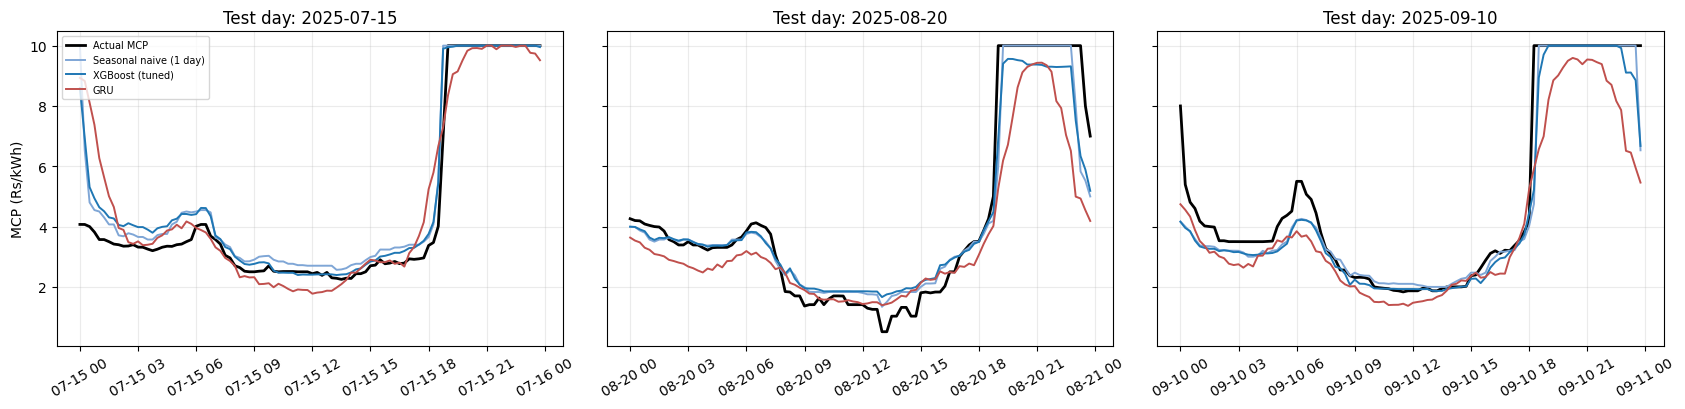


==================== MARKET INSIGHTS (15-min blocks, test) ====================
            Regime / window  Blocks  Mean actual MCP  MAE XGBoost (tuned)  MAE seasonal naive  Gain %
            All test blocks    8928            3.925                0.555               0.772  28.156
  Solar hours (10:00-15:59)    2232            1.686                0.396               0.564  29.839
 Evening peak (18:00-22:59)    1860            7.685                0.955               1.559  38.737
Blocks at the price ceiling    1163           10.000                0.725               1.135  36.122

MAE by regime, all models (15-min, Rs/kWh):
                                            All test blocks  Solar hours (10:00-15:59)  Evening peak (18:00-22:59)  Blocks at the price ceiling
XGBoost (tuned)                                       0.518                      0.377                       0.837                        0.753
XGB v2                                                0.534                 

In [163]:
# ===== PART 21 | CELL 21.1: final comparison, plots and market insights =====
import matplotlib.pyplot as plt

# 0. one dictionary with every model's 15-minute forecast (all clipped to [0, ceiling])
PRED_ALL = dict(CLIPPED)
NAME_MAP = {'XGB v2': 'XGB v2', 'XGB v2 delta': 'XGB v2 delta', 'XGB v2 delta recency': 'XGB v2 delta recency',
            'LGBM v2 delta': 'LightGBM v2 delta', 'LGBM v2 delta recency': 'LightGBM v2 delta recency'}
if 'P' in globals():
    for k, nm in NAME_MAP.items():
        if k in P: PRED_ALL[nm] = P[k].reindex(dam.index)
if 'ens' in globals(): PRED_ALL['Ensemble (XGB + XGB v2 + LGBM v2)'] = ens.reindex(dam.index)
PRED_ALL = {k: v for k, v in PRED_ALL.items() if k in set(pd.DataFrame(RESULTS)['model'])}

# 1. final tables (15-min and hourly) + gain over the seasonal-naive benchmark
res_15m, res_hr = results_table('test', '15-min'), results_table('test', 'hourly')
ref = res_hr.loc['Seasonal naive (1 day)', 'MAE']
res_hr['MAE gain vs seasonal naive (%)'] = ((ref - res_hr['MAE']) / ref * 100).round(1)
print('==================== FINAL TEST METRICS (15-MIN) ===================='); print(res_15m.to_string())
print('\n==================== FINAL TEST METRICS (HOURLY) ===================='); print(res_hr.to_string())
res_15m.to_csv(f'{OUT}/metrics/final_comparison_15min_all.csv'); res_hr.to_csv(f'{OUT}/metrics/final_comparison_hourly_all.csv')

# choose the "best model" by VALIDATION error (not test), so the report is not tuned on the test set
best_name = 'XGBoost (tuned)'      # final model, fixed before the v2 experiments; v2 models did not beat it on test (DM p<0.01)
print(f'\nFinal model: {best_name}  (test hourly MAE {res_hr.loc[best_name, "MAE"]:.3f})')
# 2. forecast plot on three test days: baseline vs the main models
show = list(dict.fromkeys(['Seasonal naive (1 day)', 'XGBoost (tuned)', best_name, 'GRU']))
show = [s for s in show if s in PRED_ALL]
colors = ['#7fa6d6', '#1f77b4', '#c0504d', '#7a5cc2']
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, dday in zip(axes, ['2025-07-15', '2025-08-20', '2025-09-10']):
    ax.plot(dam['mcp'].loc[dday], color='black', lw=2, label='Actual MCP')
    for s, c in zip(show, colors): ax.plot(PRED_ALL[s].loc[dday], color=c, lw=1.4, label=s)
    ax.set_title(f'Test day: {dday}'); ax.tick_params(axis='x', rotation=30); ax.grid(alpha=.25)
axes[0].set_ylabel('MCP (Rs/kWh)'); axes[0].legend(fontsize=7, loc='upper left')
plt.tight_layout(); plt.savefig(f'{OUT}/figures/final_model_comparison.png', dpi=150, bbox_inches='tight'); plt.show()

# 3. market insights for the best model, with the seasonal-naive benchmark next to it
base_pred = PRED_ALL['Seasonal naive (1 day)']
A = pd.DataFrame({'actual': test['mcp'], 'pred': best_pred.reindex(test.index), 'base': base_pred.reindex(test.index)}).dropna()
A['err'], A['err_base'], A['hour'] = (A.actual - A.pred).abs(), (A.actual - A.base).abs(), A.index.hour
cap_t = cap.reindex(A.index).fillna(False).astype(bool) if 'cap' in globals() else (A['actual'] >= CEIL - 0.05)   # exact ceiling block (10 now, 12 earlier)
windows = {'All test blocks': np.ones(len(A), bool), 'Solar hours (10:00-15:59)': A.hour.between(10, 15).values,
           'Evening peak (18:00-22:59)': A.hour.between(18, 22).values, 'Blocks at the price ceiling': cap_t.values}
rows = []
for nm, m in windows.items():
    s = A[m]; rows.append({'Regime / window': nm, 'Blocks': len(s), 'Mean actual MCP': s.actual.mean(),
                           f'MAE {best_name}': s.err.mean(), 'MAE seasonal naive': s.err_base.mean(),
                           'Gain %': (s.err_base.mean() - s.err.mean()) / s.err_base.mean() * 100})
insights = pd.DataFrame(rows).round(3)
print('\n==================== MARKET INSIGHTS (15-min blocks, test) ===================='); print(insights.to_string(index=False))
insights.to_csv(f'{OUT}/metrics/final_insights_summary.csv', index=False)

# 4. the same windows for EVERY model (which model is good where?)
by_win = pd.DataFrame({nm: {mn: (A.actual - pr.reindex(A.index)).abs()[m].mean() for mn, pr in PRED_ALL.items()} for nm, m in windows.items()}).round(3)
print('\nMAE by regime, all models (15-min, Rs/kWh):'); print(by_win.sort_values('All test blocks').to_string())
by_win.sort_values('All test blocks').to_csv(f'{OUT}/metrics/final_mae_by_regime_all_models.csv')

# 5. worst days, with context (was it a big jump from yesterday? did we over- or under-forecast?)
dmean_all = dam['mcp'].groupby(dam.index.normalize()).mean()
g = A.groupby(A.index.normalize()).agg(actual_mean=('actual', 'mean'), pred_mean=('pred', 'mean'), MAE=('err', 'mean'))
g['bias (pred-actual)'] = g.pred_mean - g.actual_mean
g['weekday'] = g.index.day_name()
g['actual change vs yesterday'] = dmean_all.diff().reindex(g.index)
worst = g.sort_values('MAE', ascending=False).head(5).round(3)
print('\nTop 5 highest-error test days (for Limitations & Discussion):'); print(worst.to_string())
worst.to_csv(f'{OUT}/metrics/final_worst_days.csv')

In [164]:
import shutil, os
pk = f'{OUT}/repo_pack'
shutil.rmtree(pk, ignore_errors=True)
os.makedirs(f'{pk}/models')
for sub in ['figures', 'metrics', 'forecasts']:
    shutil.copytree(f'{OUT}/{sub}', f'{pk}/{sub}')
for fn in ['xgboost_deploy.json', 'model_card.json']:
    shutil.copy(f'{OUT}/data/{fn}', f'{pk}/models/{fn}')
shutil.make_archive(f'{OUT}/repo_files', 'zip', pk)
print('Created:', f'{OUT}/repo_files.zip', round(os.path.getsize(f'{OUT}/repo_files.zip') / 1e6, 1), 'MB')

Created: /kaggle/working/repo_files.zip 4.8 MB
